# Proyecto I – Preparación del dataset y EDA inicial
## 1. Introducción

**Problema:** en Colombia una parte importante de los ocupados no cotiza a pensión, y eso deja a muchas personas sin protección en la vejez.

**Pregunta del proyecto:** ¿qué probabilidad tiene un trabajador colombiano de cotizar a pensión, según su perfil?

**Variable objetivo:** `cotiza_pension` (P6920 en la GEIH): 1 = cotiza, 0 = no cotiza. Los ya pensionados (código 3) se excluyen.

**Para qué sirve:** fondos de pensiones, Colpensiones, UGPP y política pública. También permite medir cuántos trabajadores ganan 1 SMMLV o más y aun así no cotizan.

**Fuente:** Gran Encuesta Integrada de Hogares (GEIH) 2025, DANE, módulo de ocupados.

**Alcance de esta fase:** solo preparación de datos y EDA (incluido el EDA complementario de la sección 8). El modelado (regresión logística y boosting, con entrenamiento enero–septiembre y prueba octubre–diciembre) viene después.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter


def miles(x, pos=None):
    """Muestra un número con punto como separador de miles: 195169 -> 195.169."""
    return f'{x:,.0f}'.replace(',', '.')


eje_miles = FuncFormatter(miles)  # para los ejes que muestran número de personas


def coma(x, decimales=1):
    """Muestra un número con coma decimal y punto de miles: 58.8 -> 58,8; 1234.5 -> 1.234,5."""
    texto = f'{x:,.{decimales}f}'
    return texto.replace(',', '_').replace('.', ',').replace('_', '.')


eje_decimal = FuncFormatter(lambda x, pos: f'{x:g}'.replace('.', ','))  # ejes con decimales


def barras(serie, horizontal=False, ax=None, color=None):
    """Barras de una serie con Seaborn. En las horizontales, la última fila queda arriba."""
    serie = serie.iloc[::-1] if horizontal else serie
    categorias = serie.index.astype(str)
    valores = serie.to_numpy()
    ejes = {'x': valores, 'y': categorias, 'orient': 'h'} if horizontal else {'x': categorias, 'y': valores, 'orient': 'v'}
    ax = sns.barplot(**ejes, order=list(categorias), color=color, saturation=1, width=0.5, errorbar=None, ax=ax)
    ax.set_xlabel('' if horizontal else (serie.index.name or ''))
    ax.set_ylabel((serie.index.name or '') if horizontal else '')
    ax.grid(True)
    return ax


def barras_agrupadas(tabla, ax, paleta, ancho=0.5):
    """Barras lado a lado con Seaborn: una por columna de `tabla`, agrupadas por fila."""
    largo = (tabla.rename_axis(index='categoria', columns='cotiza_pension')
                  .stack().rename('valor').reset_index())
    sns.barplot(data=largo, x='categoria', y='valor', hue='cotiza_pension', order=list(tabla.index),
                hue_order=list(tabla.columns), palette=paleta, saturation=1, width=ancho, errorbar=None, ax=ax)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.grid(True)
    return ax

## 2. Carga de datos

In [2]:
from cotiza_pension.config import RAW_PATH

ruta = RAW_PATH
df = pd.read_csv(ruta)
df.shape

(358029, 26)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 358029 entries, 0 to 358028
Data columns (total 26 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   anio         358029 non-null  int64  
 1   mes          358029 non-null  int64  
 2   DIRECTORIO   358029 non-null  int64  
 3   SECUENCIA_P  358029 non-null  int64  
 4   ORDEN        358029 non-null  int64  
 5   HOGAR        358029 non-null  int64  
 6   MES          358029 non-null  int64  
 7   DPTO         358029 non-null  int64  
 8   CLASE        358029 non-null  int64  
 9   FEX_C18      358029 non-null  float64
 10  P6040        358029 non-null  int64  
 11  P3271        358029 non-null  int64  
 12  P6050        358029 non-null  int64  
 13  P6070        358029 non-null  float64
 14  P3042        358029 non-null  float64
 15  OCI          358029 non-null  float64
 16  P6920        358029 non-null  float64
 17  P6430        358029 non-null  float64
 18  P3069        358029 non-null  float

In [4]:
df.head()

,anio,mes,DIRECTORIO,SECUENCIA_P,ORDEN,HOGAR,MES,DPTO,CLASE,FEX_C18,...,P6920,P6430,P3069,P6880,P6800,P6426,P6440,INGLABO,RAMA2D_R4,P4030S1A1
0,2025,1,8086872,1,1,1,1,13,2,2184.752283,...,2.0,3.0,1.0,2.0,24.0,10.0,1.0,1040000.0,97.0,2.0
1,2025,1,8086874,1,2,1,1,13,2,1208.490211,...,2.0,4.0,1.0,8.0,60.0,480.0,2.0,700000.0,1.0,2.0
2,2025,1,8086874,1,3,1,1,13,2,1208.490211,...,2.0,1.0,2.0,8.0,50.0,12.0,1.0,1450000.0,1.0,2.0
3,2025,1,8086876,1,2,1,1,13,2,2420.064922,...,2.0,4.0,1.0,1.0,40.0,216.0,2.0,350000.0,47.0,2.0
4,2025,1,8086876,1,3,1,1,13,2,2420.064922,...,2.0,7.0,2.0,8.0,50.0,144.0,1.0,1350000.0,1.0,2.0


## 3. Diccionario de datos

Columna nueva, código original del DANE, descripción y si entra al modelo.

| Columna nueva | Código DANE | Descripción | ¿Entra al modelo? |
|---|---|---|---|
| anio | anio | Año de la encuesta (2025) | No (constante) |
| mes | mes / MES | Mes de la encuesta | No como variable; se usa para el split temporal |
| directorio | DIRECTORIO | Identificador de la vivienda | No (identificador) |
| secuencia_p | SECUENCIA_P | Identificador de la secuencia | No (identificador) |
| orden | ORDEN | Número de la persona en el hogar | No (identificador) |
| hogar | HOGAR | Número del hogar en la vivienda | No (identificador) |
| departamento | DPTO | Departamento | Sí |
| zona | CLASE | Cabecera (urbano) o resto (rural) | Sí |
| factor_expansion | FEX_C18 | Factor de expansión de la encuesta | No (se usa para estimar totales) |
| edad | P6040 | Edad en años | Sí |
| sexo | P3271 | Sexo | Sí |
| parentesco_jefe | P6050 | Parentesco con el jefe(a) del hogar | Sí |
| estado_civil | P6070 | Estado civil | Sí |
| nivel_educativo | P3042 | Nivel educativo más alto alcanzado | Sí |
| (se elimina) | OCI | Ocupado (siempre 1 en este archivo) | No (constante) |
| cotiza_pension | P6920 | ¿Cotiza a un fondo de pensiones? | Variable objetivo |
| posicion_ocupacional | P6430 | Posición ocupacional en el trabajo | Sí |
| tamano_empresa | P3069 | Cantidad de personas en la empresa o negocio | Sí |
| lugar_trabajo | P6880 | Lugar donde realiza el trabajo (código) | Sí |
| horas_semana | P6800 | Horas trabajadas a la semana | Sí |
| meses_en_empresa | P6426 | Meses trabajando en la empresa o negocio | Sí |
| tiene_contrato | P6440 | ¿Tiene contrato? (1 = sí, 0 = no) | Se prueba con y sin ella |
| ingreso | INGLABO | Ingreso laboral mensual (pesos) | No directo; se usa `ingreso_smmlv` |
| ingreso_smmlv | (calculada) | Ingreso dividido por el SMMLV 2025 | Sí |
| gana_1_smmlv_o_mas | (calculada) | 1 si ingreso ≥ 1 SMMLV, 0 si no | Para análisis; el modelo usa `ingreso_smmlv` |
| rama_2d | RAMA2D_R4 | Rama de actividad (CIIU Rev. 4, 2 dígitos) | Sí |
| estrato | P4030S1A1 | Estrato de la vivienda (energía eléctrica) | Sí |

**Origen del diccionario.** El archivo crudo solo trae códigos (P6800, P3042, etc.), sin descripciones, y los metadatos que vienen con los datos descargados (`metadata/2025.json`) solo describen la encuesta en general, no cada variable. Por eso los nombres y las categorías de la tabla salen del cuestionario y los diccionarios de la GEIH del DANE, tal como los conozco, y **no de un archivo incluido en el proyecto**. Para no depender solo de eso, se contrastaron con los datos:

- **Confirmadas con los datos:** `estado_civil` (edad promedio de cada código: unión libre reciente 31 años, viudo(a) 60), `posicion_ocupacional` (los familiares sin remuneración, código 6, no tienen ingreso; los empleados de empresa y del gobierno tienen contrato), `tamano_empresa` (el código 1 son casi todos cuenta propia y la cotización sube con cada código), `nivel_educativo` (la cotización sube con el nivel), `departamento`, `zona`, `sexo`, `edad`, `horas_semana` (mediana de 46 horas) e `ingreso` (el valor más repetido es 1.423.500, el SMMLV 2025).
- **Deducidas, por confirmar:** los códigos 9 y 10 de `tamano_empresa`, los códigos 7 y 8 de `posicion_ocupacional`, y el sentido de 1/2 en `tiene_contrato`.
- **Sin confirmar, por eso no se tradujeron:** `parentesco_jefe` (más allá de jefe, pareja e hijo), `lugar_trabajo` y los valores 0 y 9 de `estrato`.

Antes de entregar el proyecto conviene revisar estos puntos contra el diccionario oficial de la GEIH 2025 en la página del DANE.

## 4. Limpieza

Primero se eliminan `MES` (idéntica a `mes`, solo cambia la mayúscula) y `OCI` (todos son ocupados). Luego se pasan los nombres a minúscula con nombres claros.

In [5]:
print((df['mes'] != df['MES']).sum())
print(df['OCI'].unique())

0
[1.]


In [6]:
df = df.drop(columns=['MES', 'OCI'])
df.columns = df.columns.str.lower()

df = df.rename(columns={
    'dpto': 'departamento',
    'clase': 'zona',
    'fex_c18': 'factor_expansion',
    'p6040': 'edad',
    'p3271': 'sexo',
    'p6050': 'parentesco_jefe',
    'p6070': 'estado_civil',
    'p3042': 'nivel_educativo',
    'p6920': 'cotiza_pension',
    'p6430': 'posicion_ocupacional',
    'p3069': 'tamano_empresa',
    'p6880': 'lugar_trabajo',
    'p6800': 'horas_semana',
    'p6426': 'meses_en_empresa',
    'p6440': 'tiene_contrato',
    'inglabo': 'ingreso',
    'rama2d_r4': 'rama_2d',
    'p4030s1a1': 'estrato',
})
df.columns.tolist()

['anio',
 'mes',
 'directorio',
 'secuencia_p',
 'orden',
 'hogar',
 'departamento',
 'zona',
 'factor_expansion',
 'edad',
 'sexo',
 'parentesco_jefe',
 'estado_civil',
 'nivel_educativo',
 'cotiza_pension',
 'posicion_ocupacional',
 'tamano_empresa',
 'lugar_trabajo',
 'horas_semana',
 'meses_en_empresa',
 'tiene_contrato',
 'ingreso',
 'rama_2d',
 'estrato']

**Números.** Se verifica el tipo de las columnas numéricas. El factor de expansión ya se leyó como número con punto decimal (no tiene comas); se deja como `float`.

In [7]:
columnas_numericas = ['factor_expansion', 'ingreso', 'edad', 'horas_semana', 'meses_en_empresa']
print(df[columnas_numericas].dtypes)

df[columnas_numericas].describe()

factor_expansion    float64
ingreso             float64
edad                  int64
horas_semana        float64
meses_en_empresa    float64
dtype: object


,factor_expansion,ingreso,edad,horas_semana,meses_en_empresa
count,358029.000000,3.498300e+05,358029.000000,358029.000000,358029.000000
mean,798.620241,1.764269e+06,41.890408,43.581478,84.601178
std,1131.154344,2.232395e+06,14.180345,12.981913,111.223761
min,6.703899,0.000000e+00,15.000000,1.000000,0.000000
25%,161.529877,8.000000e+05,30.000000,40.000000,12.000000
50%,328.868619,1.423500e+06,41.000000,46.000000,36.000000
75%,961.490374,1.900000e+06,52.000000,48.000000,120.000000
max,17668.825277,1.030000e+08,100.000000,130.000000,950.000000


**Pensionados y variable objetivo.** En P6920: 1 = sí cotiza, 2 = no cotiza, 3 = ya pensionado. Se quitan los pensionados y se deja 1/0.

In [8]:
print(df['cotiza_pension'].value_counts())

df = df[df['cotiza_pension'] != 3].copy()
df['cotiza_pension'] = df['cotiza_pension'].map({1: 1, 2: 0})

df['cotiza_pension'].value_counts()

cotiza_pension
2.0    200796
1.0    150925
3.0      6308
Name: count, dtype: int64


cotiza_pension
0    200796
1    150925
Name: count, dtype: int64

**Códigos a palabras.** Se usan los códigos de la GEIH. Algunas categorías se confirmaron con los datos (por ejemplo, la edad promedio de cada estado civil y los ingresos de cada posición ocupacional). Los códigos que no se pudieron confirmar se dejaron agrupados o sin cambiar, y se avisa en las conclusiones.

In [9]:
df['sexo'] = df['sexo'].map({1: 'Hombre', 2: 'Mujer'})

df['zona'] = df['zona'].map({1: 'Urbano', 2: 'Rural'})

df['estado_civil'] = df['estado_civil'].map({
    1: 'Unión libre menos de 2 años',
    2: 'Unión libre 2 años o más',
    3: 'Casado(a)',
    4: 'Separado(a) o divorciado(a)',
    5: 'Viudo(a)',
    6: 'Soltero(a)',
})

df['nivel_educativo'] = df['nivel_educativo'].map({
    1: 'Ninguno',
    2: 'Preescolar',
    3: 'Básica primaria',
    4: 'Básica secundaria',
    5: 'Media académica',
    6: 'Media técnica',
    7: 'Normalista',
    8: 'Técnica profesional',
    9: 'Tecnológica',
    10: 'Universitaria',
    11: 'Especialización',
    12: 'Maestría',
    13: 'Doctorado',
    99: 'No sabe',
})

df['posicion_ocupacional'] = df['posicion_ocupacional'].map({
    1: 'Empleado empresa particular',
    2: 'Empleado del gobierno',
    3: 'Empleado doméstico',
    4: 'Cuenta propia',
    5: 'Patrón o empleador',
    6: 'Familiar sin remuneración',
    7: 'Jornalero o peón',
    8: 'Otro',
})

df['tamano_empresa'] = df['tamano_empresa'].map({
    1: 'Trabaja solo',
    2: '2 a 3',
    3: '4 a 5',
    4: '6 a 10',
    5: '11 a 19',
    6: '20 a 30',
    7: '31 a 50',
    8: '51 a 100',
    9: '101 a 200',
    10: '201 o más',
})

df['parentesco_jefe'] = df['parentesco_jefe'].map({
    1: 'Jefe(a) del hogar',
    2: 'Pareja del jefe(a)',
    3: 'Hijo(a)',
}).fillna('Otro')

df['tiene_contrato'] = df['tiene_contrato'].map({1: 1, 2: 0})

df['departamento'] = df['departamento'].map({
    5: 'Antioquia', 8: 'Atlántico', 11: 'Bogotá D.C.', 13: 'Bolívar', 15: 'Boyacá',
    17: 'Caldas', 18: 'Caquetá', 19: 'Cauca', 20: 'Cesar', 23: 'Córdoba',
    25: 'Cundinamarca', 27: 'Chocó', 41: 'Huila', 44: 'La Guajira', 47: 'Magdalena',
    50: 'Meta', 52: 'Nariño', 54: 'Norte de Santander', 63: 'Quindío', 66: 'Risaralda',
    68: 'Santander', 70: 'Sucre', 73: 'Tolima', 76: 'Valle del Cauca', 81: 'Arauca',
    85: 'Casanare', 86: 'Putumayo', 88: 'San Andrés', 91: 'Amazonas', 94: 'Guainía',
    95: 'Guaviare', 97: 'Vaupés', 99: 'Vichada',
})

df[['sexo', 'zona', 'estado_civil', 'nivel_educativo', 'posicion_ocupacional',
    'tamano_empresa', 'parentesco_jefe', 'tiene_contrato', 'departamento']].isna().sum()

sexo                    0
zona                    0
estado_civil            0
nivel_educativo         0
posicion_ocupacional    0
tamano_empresa          0
parentesco_jefe         0
tiene_contrato          0
departamento            0
dtype: int64

Si algún valor no estaba en el diccionario, aparecería arriba como nulo. Todos los conteos deben ser cero.

**Ingreso en SMMLV.** El salario mínimo mensual de 2025 es de $1.423.500 (también es el valor más repetido en `ingreso`). Si el ingreso es nulo, `gana_1_smmlv_o_mas` también queda nulo.

In [10]:
smmlv = 1423500

df['ingreso_smmlv'] = df['ingreso'] / smmlv
df['gana_1_smmlv_o_mas'] = (df['ingreso_smmlv'] >= 1).astype(float)
df.loc[df['ingreso'].isna(), 'gana_1_smmlv_o_mas'] = None

df[['ingreso', 'ingreso_smmlv', 'gana_1_smmlv_o_mas']].describe()

,ingreso,ingreso_smmlv,gana_1_smmlv_o_mas
count,3.438050e+05,343805.000000,343805.000000
mean,1.747716e+06,1.227760,0.516636
std,2.174840e+06,1.527812,0.499724
min,0.000000e+00,0.000000,0.000000
25%,8.000000e+05,0.561995,0.000000
50%,1.423500e+06,1.000000,1.000000
75%,1.900000e+06,1.334738,1.000000
max,1.030000e+08,72.356867,1.000000


In [11]:
print(df.shape)
df.head()

(351721, 26)


,anio,mes,directorio,secuencia_p,orden,hogar,departamento,zona,factor_expansion,edad,...,tamano_empresa,lugar_trabajo,horas_semana,meses_en_empresa,tiene_contrato,ingreso,rama_2d,estrato,ingreso_smmlv,gana_1_smmlv_o_mas
0,2025,1,8086872,1,1,1,Bolívar,Rural,2184.752283,54,...,Trabaja solo,2.0,24.0,10.0,1,1040000.0,97.0,2.0,0.730594,0.0
1,2025,1,8086874,1,2,1,Bolívar,Rural,1208.490211,60,...,Trabaja solo,8.0,60.0,480.0,0,700000.0,1.0,2.0,0.491746,0.0
2,2025,1,8086874,1,3,1,Bolívar,Rural,1208.490211,59,...,2 a 3,8.0,50.0,12.0,1,1450000.0,1.0,2.0,1.018616,1.0
3,2025,1,8086876,1,2,1,Bolívar,Rural,2420.064922,45,...,Trabaja solo,1.0,40.0,216.0,0,350000.0,47.0,2.0,0.245873,0.0
4,2025,1,8086876,1,3,1,Bolívar,Rural,2420.064922,44,...,2 a 3,8.0,50.0,144.0,1,1350000.0,1.0,2.0,0.948367,0.0


## 5. Variables excluidas por fuga de información

Hay variables de la GEIH que se contestan **solo si la persona ya cotiza**, o que son una consecuencia directa de cotizar. Si entraran al modelo, este "vería" la respuesta y las predicciones serían inútiles para el uso real. Por eso **no se usan**:

- **Fondo al que cotiza:** solo lo responde quien cotiza.
- **Quién paga el aporte:** igual, solo aplica a quien cotiza.
- **Régimen de salud contributivo:** en Colombia está atado a la relación laboral formal; quien cotiza a pensión casi siempre está en el contributivo.
- **ARL (riesgos laborales):** se afilia junto con salud y pensión.
- **Caja de compensación:** también viene con el empleo formal.
- **Informalidad del DANE:** se construye usando, entre otras cosas, si cotiza a pensión.

El archivo crudo que se recibió ya no trae estas columnas, así que no hay que quitarlas.

**`tiene_contrato`** se deja en el dataset, pero no se descarta ni se asume buena: es muy informativa y puede estar muy ligada a la formalidad. En el modelado se probará **con y sin** esta variable para ver cuánto cambia el resultado.

## 6. Variable objetivo

In [12]:
conteo = df['cotiza_pension'].value_counts()
porcentaje = df['cotiza_pension'].value_counts(normalize=True) * 100
print(conteo)
print(porcentaje.round(1))

peso = (df['cotiza_pension'] * df['factor_expansion']).sum() / df['factor_expansion'].sum() * 100
print('Con factor de expansión cotiza:', round(peso, 1), '%')

cotiza_pension
0    200796
1    150925
Name: count, dtype: int64
cotiza_pension
0    57.1
1    42.9
Name: proportion, dtype: float64
Con factor de expansión cotiza: 44.0 %


Cotiza cerca del 43 % y no cotiza cerca del 57 %. Las clases **no están muy desbalanceadas** (hay bastantes casos de ambas), así que no hace falta remuestrear; para el modelado basta con medir con métricas como AUC, no solo exactitud.

## 7. EDA básico

**Nulos por columna.**

In [13]:
nulos = df.isna().mean() * 100
nulos = nulos[nulos > 0].sort_values()
print(nulos.round(2))

estrato               0.43
ingreso               2.25
ingreso_smmlv         2.25
gana_1_smmlv_o_mas    2.25
dtype: float64


Solo `ingreso` y `estrato` tienen nulos propios (2,25 % y 0,43 %). `ingreso_smmlv` y `gana_1_smmlv_o_mas` se calculan desde `ingreso`, por eso tienen exactamente los mismos nulos. Los nulos de ingreso son sobre todo familiares sin remuneración.

**% que cotiza por mes.**

In [14]:
por_mes = df.groupby('mes')['cotiza_pension'].mean() * 100
print(por_mes.round(1))

mes
1     42.5
2     42.1
3     42.1
4     43.3
5     42.9
6     43.7
7     43.1
8     43.4
9     43.6
10    42.8
11    42.8
12    42.5
Name: cotiza_pension, dtype: float64


La tasa se mantiene bastante estable durante el año, sin saltos fuertes entre los meses de entrenamiento (1–9) y de prueba (10–12).

**% que cotiza por edad.**

In [15]:
grupo_edad = pd.cut(df['edad'], bins=[14, 24, 34, 44, 54, 64, 120],
                    labels=['15-24', '25-34', '35-44', '45-54', '55-64', '65+'])
por_edad = df.groupby(grupo_edad, observed=True)['cotiza_pension'].mean() * 100
print(por_edad.round(1))

edad
15-24    34.8
25-34    51.8
35-44    50.5
45-54    44.0
55-64    33.1
65+      10.2
Name: cotiza_pension, dtype: float64


La cotización sube hasta cerca de 52 % entre los 25 y 34 años, se mantiene en 50 % hasta los 44 y luego baja: 44 % a los 45–54, 33 % a los 55–64 y solo 10 % después de los 65.

**% que cotiza por sexo.**

In [16]:
por_sexo = df.groupby('sexo')['cotiza_pension'].mean() * 100
print(por_sexo.round(1))

sexo
Hombre    41.2
Mujer     45.1
Name: cotiza_pension, dtype: float64


Las mujeres cotizan un poco más que los hombres (45 % frente a 41 %), una diferencia pequeña comparada con la de otras variables.

**Cantidad de personas por nivel educativo**

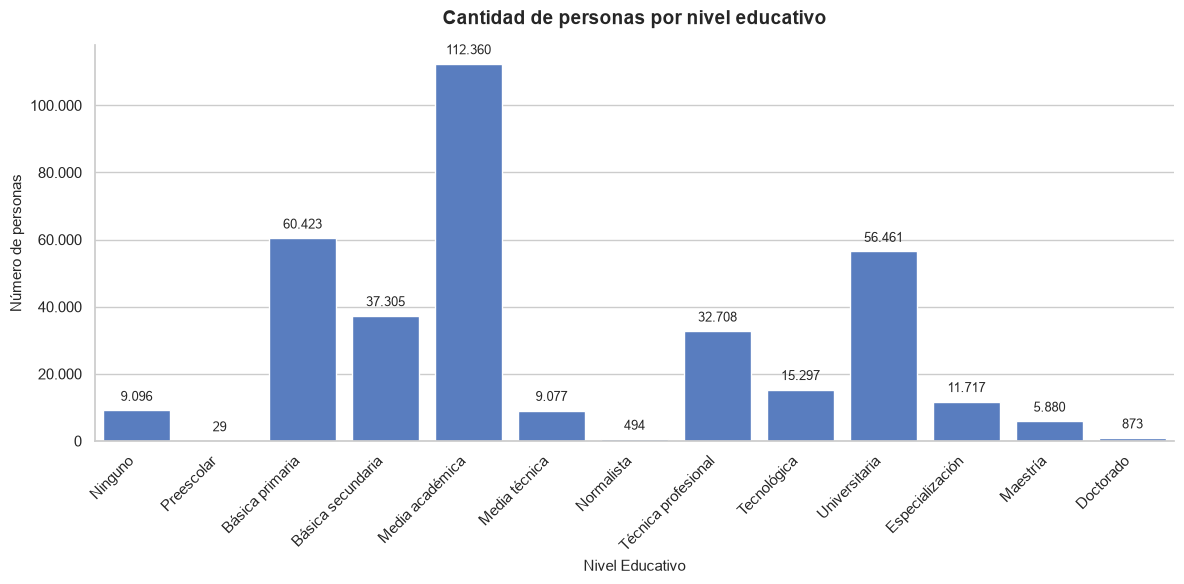

In [17]:
orden_edu = [ 'Ninguno', 'Preescolar', 'Básica primaria', 'Básica secundaria', 'Media académica', 'Media técnica', 'Normalista', 'Técnica profesional',
    'Tecnológica', 'Universitaria', 'Especialización', 'Maestría', 'Doctorado', 
]

por_edu = df.groupby('nivel_educativo')['cotiza_pension'].count()
por_edu = por_edu.reindex(orden_edu).dropna()

sns.set_theme(style='whitegrid', palette='muted')

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=por_edu.index, y=por_edu.values)

for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        miles(height),
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 5),
        textcoords='offset points',
        fontsize=9,
    )

plt.title(
    'Cantidad de personas por nivel educativo',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Nivel Educativo', fontsize=11)
plt.ylabel('Número de personas', fontsize=11)
ax.yaxis.set_major_formatter(eje_miles)
plt.xticks(rotation=45, ha='right')
sns.despine()
plt.tight_layout()
plt.show()

**% que cotiza por nivel educativo.**

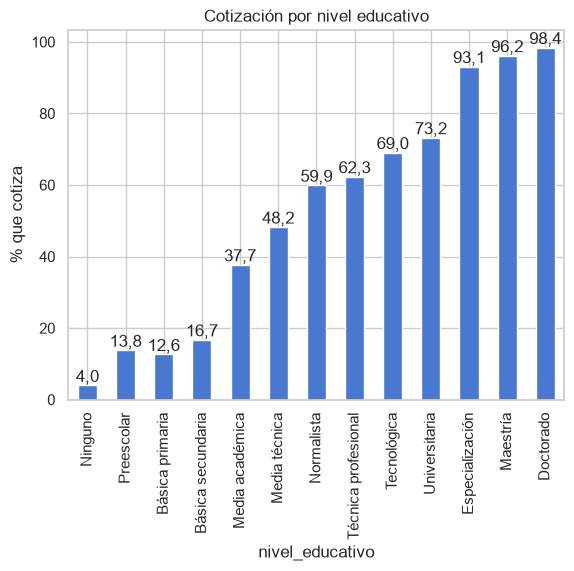

In [18]:
orden_edu = ['Ninguno', 'Preescolar', 'Básica primaria', 'Básica secundaria', 'Media académica',
             'Media técnica', 'Normalista', 'Técnica profesional', 'Tecnológica',
             'Universitaria', 'Especialización', 'Maestría', 'Doctorado']
por_edu = df.groupby('nivel_educativo')['cotiza_pension'].mean() * 100
por_edu = por_edu.reindex(orden_edu).dropna()
ax = barras(por_edu)
ax.bar_label(ax.containers[0], fmt=coma)
plt.ylabel('% que cotiza')
plt.title('Cotización por nivel educativo')
plt.xticks(rotation=90)
plt.show()

A mayor nivel educativo, mayor cotización: de 4 % sin estudios y 13 % con primaria a más de 93 % con posgrado.

**Calidad del empleo de quienes NO cotizan, por nivel educativo.** Este archivo solo trae personas ocupadas, así que no se puede comparar "con empleo" frente a "sin empleo". Aquí se mira solo a los que no cotizan y, como aproximación a la calidad de su empleo, qué parte tiene contrato y qué parte gana 1 SMMLV o más, según su nivel educativo.

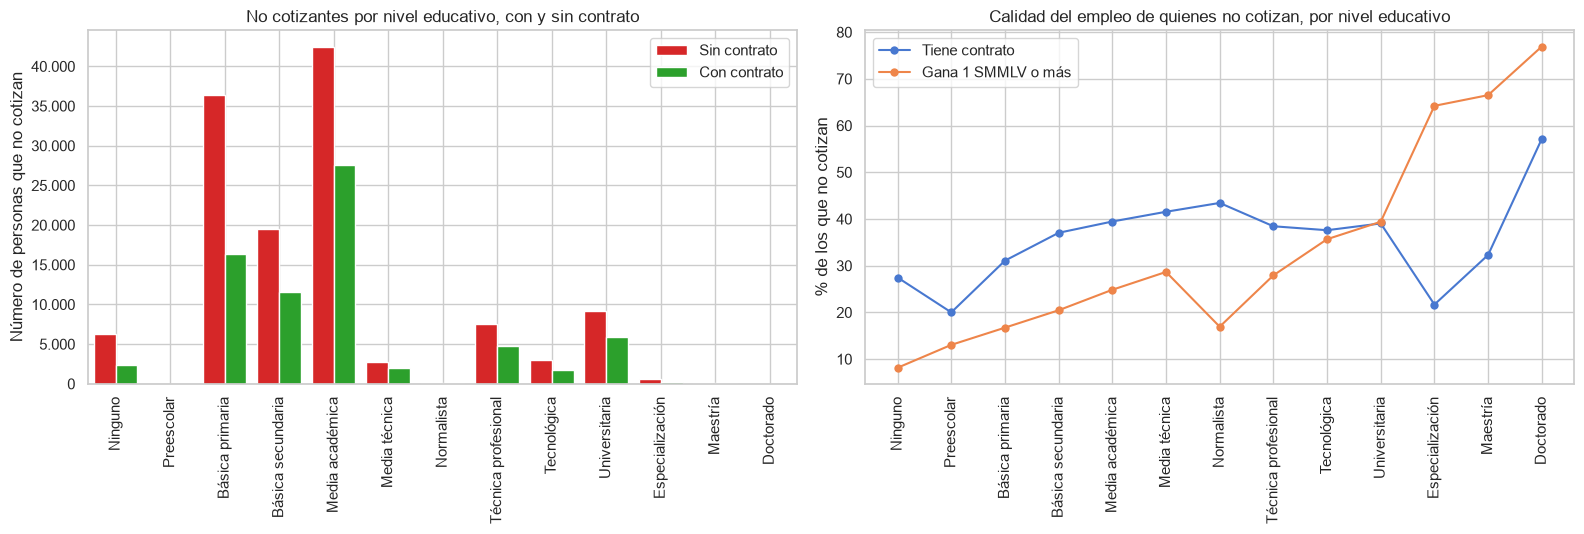

In [19]:
import numpy as np

# Solo quienes NO cotizan a pensión
d = df[(df['cotiza_pension'] == 0) & (df['nivel_educativo'].isin(orden_edu))].copy()
niveles = [n for n in orden_edu if n in d['nivel_educativo'].unique()]
x = np.arange(len(niveles))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Izquierda: cuántos no cotizantes hay por nivel educativo, con y sin contrato (barras lado a lado)
ax = axes[0]
conteo = d.groupby(['nivel_educativo', 'tiene_contrato']).size().unstack(fill_value=0).reindex(niveles)
ancho = 0.4
barras_agrupadas(conteo.rename(columns={0: 'Sin contrato', 1: 'Con contrato'}), ax,
                 ['tab:red', 'tab:green'], ancho=2 * ancho)
ax.tick_params(axis='x', rotation=90)
ax.set_ylabel('Número de personas que no cotizan')
ax.yaxis.set_major_formatter(eje_miles)
ax.set_title('No cotizantes por nivel educativo, con y sin contrato')
ax.legend()

# Derecha: calidad del empleo de los que no cotizan
ax = axes[1]
sns.lineplot(x=x, y=(d.groupby('nivel_educativo')['tiene_contrato'].mean().reindex(niveles) * 100).to_numpy(),
             marker='o', markeredgewidth=0, sort=False, estimator=None, label='Tiene contrato', ax=ax)
sns.lineplot(x=x, y=(d.groupby('nivel_educativo')['gana_1_smmlv_o_mas'].mean().reindex(niveles) * 100).to_numpy(),
             marker='o', markeredgewidth=0, sort=False, estimator=None, label='Gana 1 SMMLV o más', ax=ax)
ax.set_xticks(x)
ax.set_xticklabels(niveles, rotation=90)
ax.set_ylabel('% de los que no cotizan')
ax.set_title('Calidad del empleo de quienes no cotizan, por nivel educativo')
ax.legend()

plt.tight_layout()
plt.show()


Hay 200.796 ocupados que no cotizan. La mayoría tiene estudios bajos o medios: media académica (70.026), básica primaria (52.799) y básica secundaria (31.070) concentran cerca de tres cuartas partes del grupo. El contrato **no sube con la educación**: entre los que no cotizan, solo entre 28 % y 43 % tiene contrato en casi todos los niveles (36 % en total), así que tener contrato no garantiza cotizar. En cambio, el porcentaje que gana 1 SMMLV o más sí crece con el estudio, de 8 % sin estudios a 64–77 % en posgrado. Los posgrados casi no aparecen en este grupo (812 en especialización, 226 en maestría y 14 en doctorado), así que sus porcentajes se apoyan en pocos casos.

**Revisión por nivel educativo (todos los ocupados).** Para cada nivel educativo se mira la distribución del ingreso (histograma, separando quienes cotizan de quienes no) y una tabla resumen con las demás variables: cotiza, contrato, ingreso, zona, sexo y edad. En los histogramas solo se muestra el ingreso hasta 5 SMMLV para que se lean bien.

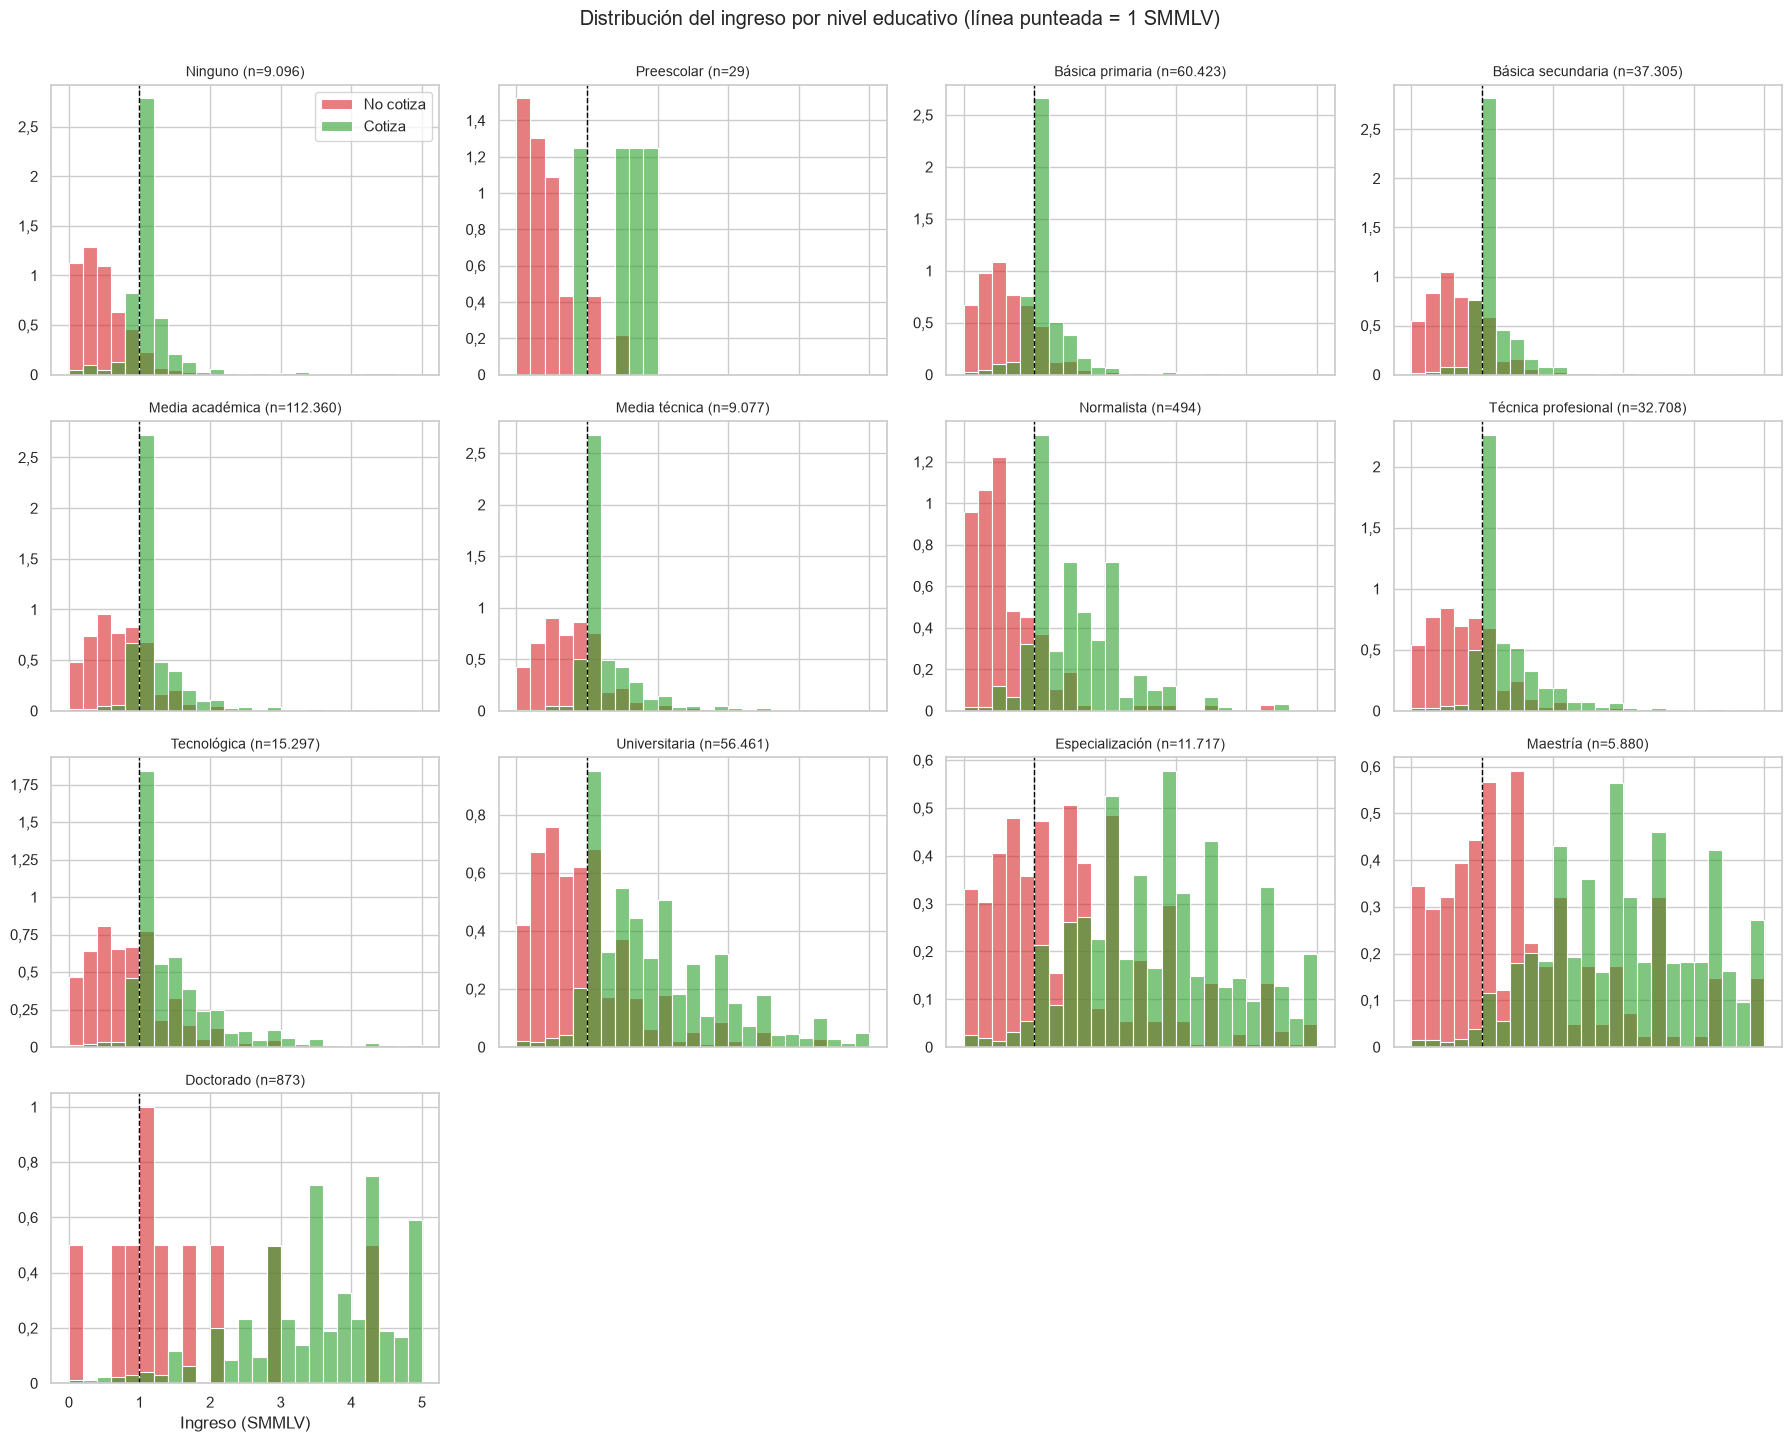

,n,cotiza,contrato,gana_1_smmlv,mediana_ingreso_smmlv,urbano,mujer,edad_media
nivel_educativo,,,,,,,,
Ninguno,9096,4.0,30.2,11.0,0.42,57.6,32.2,56.6
Preescolar,29,13.8,31.0,22.2,0.42,75.9,31.0,52.1
Básica primaria,60423,12.6,38.3,24.8,0.63,72.1,34.6,51.9
Básica secundaria,37305,16.7,46.0,30.7,0.70,83.8,36.6,42.2
Media académica,112360,37.7,59.8,47.4,0.98,90.1,42.4,38.7
Media técnica,9077,48.2,67.3,57.6,1.00,91.5,42.5,36.0
Normalista,494,59.9,76.7,60.9,1.00,88.1,75.3,40.9
Técnica profesional,32708,62.3,73.9,65.5,1.00,94.8,58.2,37.4
Tecnológica,15297,69.0,76.5,72.8,1.12,96.0,49.8,37.1


In [20]:
import numpy as np

todos = df[df['nivel_educativo'].isin(orden_edu)].copy()
niveles_t = [n for n in orden_edu if n in todos['nivel_educativo'].unique()]

# Histogramas del ingreso (en SMMLV) por nivel educativo, cotiza vs no cotiza
filas = int(np.ceil(len(niveles_t) / 4))
fig, axes = plt.subplots(filas, 4, figsize=(18, 3.6 * filas), sharex=True)
axes = axes.ravel()
bins = np.linspace(0, 5, 26)

for ax, nivel in zip(axes, niveles_t):
    sub = todos[todos['nivel_educativo'] == nivel]
    ing_no = sub.loc[sub['cotiza_pension'] == 0, 'ingreso_smmlv'].dropna()
    ing_si = sub.loc[sub['cotiza_pension'] == 1, 'ingreso_smmlv'].dropna()
    sns.histplot(ing_no, bins=bins, stat='density', alpha=0.6, color='tab:red', label='No cotiza', ax=ax)
    sns.histplot(ing_si, bins=bins, stat='density', alpha=0.6, color='tab:green', label='Cotiza', ax=ax)
    ax.axvline(1, color='black', linestyle='--', linewidth=1)
    ax.set_title(f'{nivel} (n={miles(len(sub))})', fontsize=10)
    ax.set_xlabel('Ingreso (SMMLV)')
    ax.set_ylabel('')
    ax.yaxis.set_major_formatter(eje_decimal)

for ax in axes[len(niveles_t):]:
    ax.axis('off')
axes[0].legend()
fig.suptitle('Distribución del ingreso por nivel educativo (línea punteada = 1 SMMLV)', y=1.0)
plt.tight_layout()
plt.show()

# Tabla resumen por nivel educativo
resumen = todos.groupby('nivel_educativo').agg(
    n=('cotiza_pension', 'size'),
    cotiza=('cotiza_pension', 'mean'),
    contrato=('tiene_contrato', 'mean'),
    gana_1_smmlv=('gana_1_smmlv_o_mas', 'mean'),
    mediana_ingreso_smmlv=('ingreso_smmlv', 'median'),
    urbano=('zona', lambda s: (s == 'Urbano').mean()),
    mujer=('sexo', lambda s: (s == 'Mujer').mean()),
    edad_media=('edad', 'mean'),
).reindex(niveles_t)
for c in ['cotiza', 'contrato', 'gana_1_smmlv', 'urbano', 'mujer']:
    resumen[c] = (resumen[c] * 100).round(1)
resumen['mediana_ingreso_smmlv'] = resumen['mediana_ingreso_smmlv'].round(2)
resumen['edad_media'] = resumen['edad_media'].round(1)
resumen

El ingreso sube con la educación y separa a quienes cotizan de quienes no. La mediana de ingreso pasa de 0,42 SMMLV sin estudios a 1,48 en universitaria y 4,78 en doctorado. En todos los niveles la mediana de quienes cotizan es mayor que la de quienes no: por ejemplo, 1,83 frente a 0,84 SMMLV en universitaria y 1,00 frente a 0,56 en básica primaria. La cotización pasa de 4 % sin estudios a 73 % en universitaria y 98 % en doctorado.

Las otras variables acompañan ese patrón: la zona urbana pasa de 58 % a cerca de 97 % y el contrato de 30 % a 95 %. Las mujeres son minoría en los niveles bajos (31–42 % hasta media técnica) y mayoría en técnica profesional (58 %) y especialización (57 %). La edad media es más alta en los extremos (57 años sin estudios, 47 en doctorado) y ronda los 36–38 años entre media técnica y universitaria. Preescolar (29 personas), normalista (494) y doctorado (873) tienen pocos casos, así que sus porcentajes son menos estables.

**% que cotiza por posición ocupacional.**

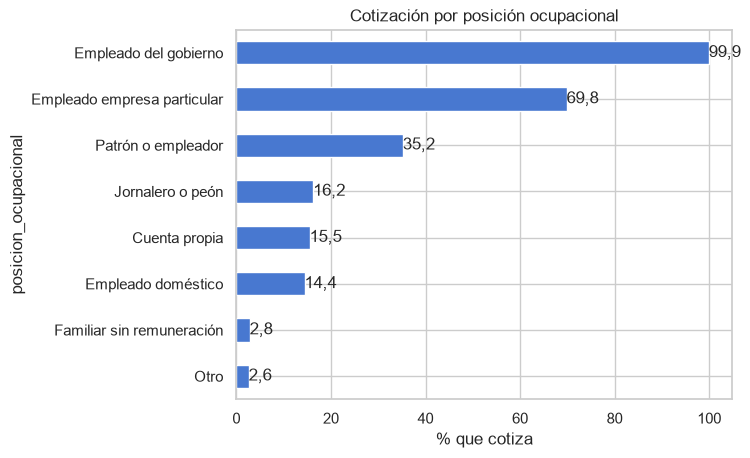

In [21]:
por_pos = df.groupby('posicion_ocupacional')['cotiza_pension'].mean() * 100
ax = barras(por_pos.sort_values(), horizontal=True)
ax.bar_label(ax.containers[0], fmt=coma)
plt.xlabel('% que cotiza')
plt.title('Cotización por posición ocupacional')
plt.show()

Casi todos los empleados del gobierno cotizan (más de 99 %) y 70 % de los de empresa particular; los patrones cotizan 35 % y cuenta propia, jornaleros, domésticos y familiares sin remuneración, menos de 17 %.

**% que cotiza por tamaño de empresa.**

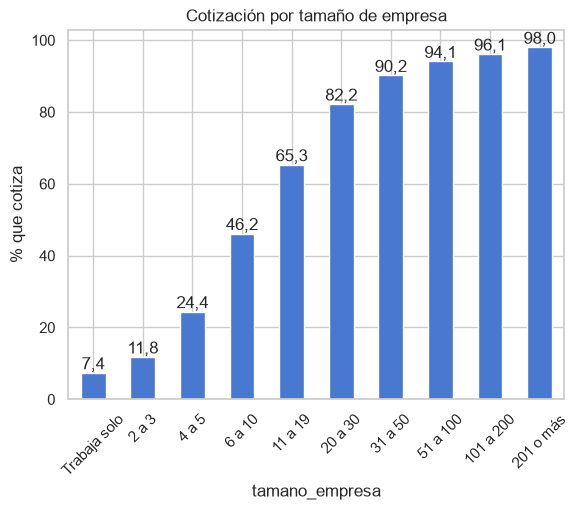

In [22]:
orden_tam = ['Trabaja solo', '2 a 3', '4 a 5', '6 a 10', '11 a 19', '20 a 30',
             '31 a 50', '51 a 100', '101 a 200', '201 o más']
por_tam = df.groupby('tamano_empresa')['cotiza_pension'].mean() * 100
por_tam = por_tam.reindex(orden_tam)
ax = barras(por_tam)
ax.bar_label(ax.containers[0], fmt=coma)
plt.ylabel('% que cotiza')
plt.title('Cotización por tamaño de empresa')
plt.xticks(rotation=45)
plt.show()

La cotización crece de forma casi continua con el tamaño: 7 % entre quienes trabajan solos, 46 % en empresas de 6 a 10 personas y más de 90 % en empresas de 31 personas o más.

**% que cotiza por zona.**

In [23]:
por_zona = df.groupby('zona')['cotiza_pension'].mean() * 100
print(por_zona.round(1))

zona
Rural     18.5
Urbano    46.3
Name: cotiza_pension, dtype: float64


En la zona urbana cotiza 46 % y en la rural solo 18 %.

**Frecuencia absoluta y relativa por sexo, según cotice o no.** Para esta sección y las siguientes, la frecuencia absoluta es el número de personas y la relativa es el porcentaje dentro de cada grupo (cada barra de la derecha suma 100 % entre "No cotiza" y "Cotiza"). La tabla agrega también el porcentaje sobre el total de ocupados. Son tablas y gráficos nuevos; el dataset no se modifica.

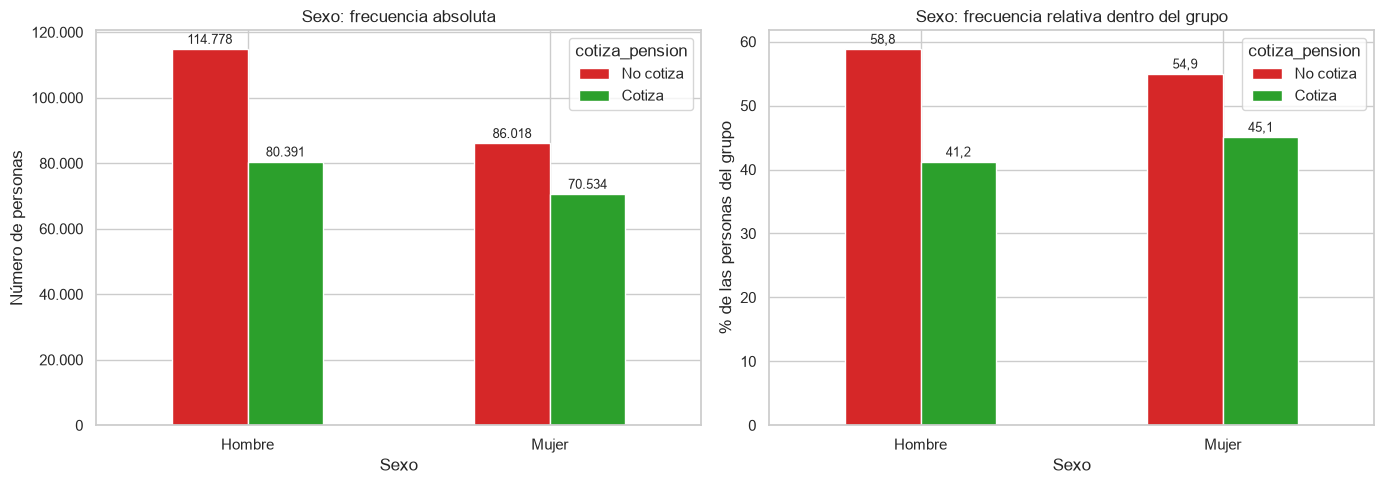

Frecuencia absoluta                % dentro del grupo         \
cotiza_pension           No cotiza Cotiza   Total          No cotiza Cotiza   
sexo                                                                          
Hombre                      114778  80391  195169               58.8   41.2   
Mujer                        86018  70534  156552               54.9   45.1   

               % del total         
cotiza_pension   No cotiza Cotiza  
sexo                               
Hombre                32.6   22.9  
Mujer                 24.5   20.1

In [24]:
etiquetas = {0: 'No cotiza', 1: 'Cotiza'}
colores = ['tab:red', 'tab:green']


def tabla_frecuencias(grupo):
    """Frecuencia absoluta y relativa de cotiza / no cotiza para cada categoría de `grupo`."""
    absoluta = pd.crosstab(grupo, df['cotiza_pension']).rename(columns=etiquetas)
    absoluta['Total'] = absoluta.sum(axis=1)
    dentro = (pd.crosstab(grupo, df['cotiza_pension'], normalize='index') * 100).round(1).rename(columns=etiquetas)
    del_total = (absoluta[['No cotiza', 'Cotiza']] / absoluta['Total'].sum() * 100).round(1)
    return pd.concat({'Frecuencia absoluta': absoluta,
                      '% dentro del grupo': dentro,
                      '% del total': del_total}, axis=1)


def graficar_frecuencias(grupo, titulo, ancho=14, rotacion=0, tam_etiqueta=9, rot_etiqueta=0):
    """Barras de frecuencia absoluta (izquierda) y relativa dentro del grupo (derecha)."""
    absoluta = pd.crosstab(grupo, df['cotiza_pension']).rename(columns=etiquetas)
    relativa = (pd.crosstab(grupo, df['cotiza_pension'], normalize='index') * 100).rename(columns=etiquetas)
    fig, axes = plt.subplots(1, 2, figsize=(ancho, 5))
    barras_agrupadas(absoluta, axes[0], colores)
    barras_agrupadas(relativa, axes[1], colores)
    for ax, fmt in zip(axes, [miles, coma]):
        for cont in ax.containers:
            ax.bar_label(cont, fmt=fmt, fontsize=tam_etiqueta, rotation=rot_etiqueta, padding=2)
        ax.tick_params(axis='x', rotation=rotacion)
        ax.set_xlabel(titulo)
    axes[0].set_ylabel('Número de personas')
    axes[0].yaxis.set_major_formatter(eje_miles)
    axes[0].set_title(f'{titulo}: frecuencia absoluta')
    axes[1].set_ylabel('% de las personas del grupo')
    axes[1].set_title(f'{titulo}: frecuencia relativa dentro del grupo')
    plt.tight_layout()
    plt.show()


graficar_frecuencias(df['sexo'], 'Sexo')
tabla_frecuencias(df['sexo'])

Hay más hombres que mujeres ocupados (195.169 frente a 156.552, es decir 55,5 % y 44,5 %), y por eso también hay más hombres entre los que no cotizan (114.778 frente a 86.018). En términos relativos, no cotiza 58,8 % de los hombres y 54,9 % de las mujeres: la diferencia es de unos 4 puntos y la cotización de las mujeres es algo mayor (45,1 % frente a 41,2 %). Con estos datos el sexo separa poco a quienes cotizan de quienes no.

**Revisión por sexo e ingreso (todos los ocupados).** Igual que con el nivel educativo: la distribución del ingreso en SMMLV (histograma, separando quienes cotizan de quienes no) y una tabla resumen con cotiza, contrato, porcentaje que gana 1 SMMLV o más y mediana de ingreso, en total y según cotice o no. Los histogramas no cortan el ingreso: solo muestran el rango de 0 a 5 SMMLV.

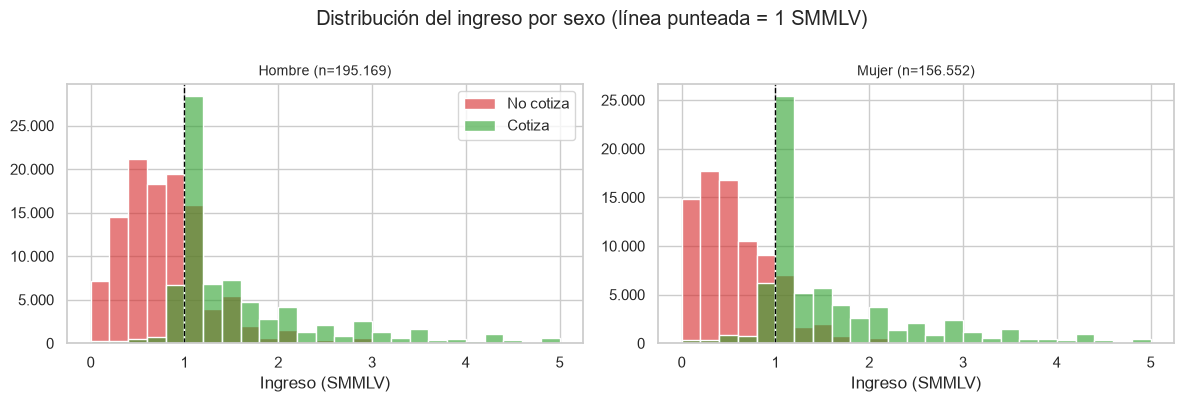

,n,cotiza,contrato,gana_1_smmlv,mediana_ingreso_smmlv,mediana_no_cotiza,mediana_cotiza
sexo,,,,,,,
Hombre,195169,41.2,57.1,53.6,1.0,0.70,1.26
Mujer,156552,45.1,64.4,49.2,1.0,0.49,1.26


In [25]:
import numpy as np


def histogramas_ingreso(grupo, titulo, columnas=3):
    """Un histograma del ingreso (en SMMLV) por categoría de `grupo`, separando cotiza / no cotiza."""
    categorias = list(grupo.cat.categories) if hasattr(grupo, 'cat') else sorted(grupo.dropna().unique())
    filas = int(np.ceil(len(categorias) / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(6 * columnas, 4 * filas), sharex=True)
    axes = np.atleast_1d(axes).ravel()
    bins = np.linspace(0, 5, 26)
    for ax, cat in zip(axes, categorias):
        sub = df[grupo == cat]
        ing_no = sub.loc[sub['cotiza_pension'] == 0, 'ingreso_smmlv'].dropna()
        ing_si = sub.loc[sub['cotiza_pension'] == 1, 'ingreso_smmlv'].dropna()
        sns.histplot(ing_no, bins=bins, alpha=0.6, color='tab:red', label='No cotiza', ax=ax)
        sns.histplot(ing_si, bins=bins, alpha=0.6, color='tab:green', label='Cotiza', ax=ax)
        ax.axvline(1, color='black', linestyle='--', linewidth=1)
        ax.set_title(f'{cat} (n={miles(len(sub))})', fontsize=10)
        ax.yaxis.set_major_formatter(eje_miles)
        ax.set_xlabel('Ingreso (SMMLV)')
        ax.set_ylabel('')
    for ax in axes[len(categorias):]:
        ax.axis('off')
    axes[0].legend()
    fig.suptitle(f'Distribución del ingreso por {titulo} (línea punteada = 1 SMMLV)', y=1.0)
    plt.tight_layout()
    plt.show()


def resumen_ingreso(grupo):
    """Tabla resumen por categoría de `grupo`: cotiza, contrato e ingreso (mediana total y según cotice)."""
    res = df.groupby(grupo, observed=True).agg(
        n=('cotiza_pension', 'size'),
        cotiza=('cotiza_pension', 'mean'),
        contrato=('tiene_contrato', 'mean'),
        gana_1_smmlv=('gana_1_smmlv_o_mas', 'mean'),
        mediana_ingreso_smmlv=('ingreso_smmlv', 'median'),
    )
    med = (df.groupby([grupo, 'cotiza_pension'], observed=True)['ingreso_smmlv'].median()
             .unstack().rename(columns={0: 'mediana_no_cotiza', 1: 'mediana_cotiza'}))
    res = res.join(med)
    for c in ['cotiza', 'contrato', 'gana_1_smmlv']:
        res[c] = (res[c] * 100).round(1)
    for c in ['mediana_ingreso_smmlv', 'mediana_no_cotiza', 'mediana_cotiza']:
        res[c] = res[c].round(2)
    return res


histogramas_ingreso(df['sexo'], 'sexo', columnas=2)
resumen_ingreso(df['sexo'])

La mediana de ingreso total es igual para hombres y mujeres (1,0 SMMLV), pero los hombres ganan 1 SMMLV o más con más frecuencia (53,6 % frente a 49,2 %), aunque las mujeres tienen contrato más a menudo (64,4 % frente a 57,1 %). La diferencia grande está entre quienes cotizan y quienes no: los cotizantes tienen una mediana de 1,26 SMMLV en ambos sexos, mientras que entre los que no cotizan es de 0,70 en los hombres y solo 0,49 en las mujeres. Es decir, la mujer que no cotiza es la que tiene el ingreso más bajo. En los histogramas, los no cotizantes se concentran por debajo de 1 SMMLV y los cotizantes se desplazan hacia la derecha. Los ingresos mayores a 5 SMMLV (1,7 % de los ocupados) quedan fuera del rango graficado.

**Frecuencia absoluta y relativa por rango de edad, según cotice o no.**

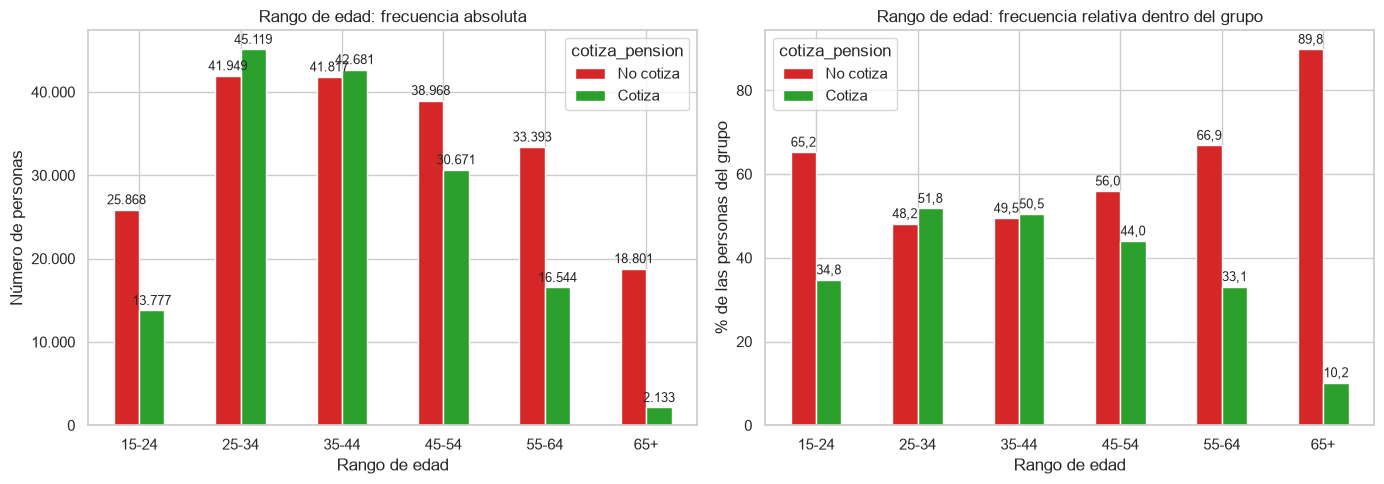

Frecuencia absoluta               % dentro del grupo         \
cotiza_pension           No cotiza Cotiza  Total          No cotiza Cotiza   
edad                                                                         
15-24                        25868  13777  39645               65.2   34.8   
25-34                        41949  45119  87068               48.2   51.8   
35-44                        41817  42681  84498               49.5   50.5   
45-54                        38968  30671  69639               56.0   44.0   
55-64                        33393  16544  49937               66.9   33.1   
65+                          18801   2133  20934               89.8   10.2   

               % del total         
cotiza_pension   No cotiza Cotiza  
edad                               
15-24                  7.4    3.9  
25-34                 11.9   12.8  
35-44                 11.9   12.1  
45-54                 11.1    8.7  
55-64                  9.5    4.7  
65+                    5.3    0.6

In [26]:
rango_edad = pd.cut(df['edad'], bins=[14, 24, 34, 44, 54, 64, 120],
                    labels=['15-24', '25-34', '35-44', '45-54', '55-64', '65+'])

graficar_frecuencias(rango_edad, 'Rango de edad')
tabla_frecuencias(rango_edad)

Los rangos de 25–34 (87.068 personas) y 35–44 años (84.498) son los más grandes y los únicos donde cotizan más de la mitad (52 % y 51 %). Los jóvenes de 15–24 años son 39.645 ocupados y solo 35 % cotiza. Desde los 45 años el porcentaje de no cotizantes sube cada vez más: 56 % en 45–54, 67 % en 55–64 y 90 % en 65 o más, donde de 20.934 ocupados solo 2.133 cotizan. En número absoluto, el mayor grupo de no cotizantes está entre 25 y 44 años (cerca de 42.000 en cada rango), aunque ahí no son mayoría; los de 55 años o más suman 52.194, algo más de la cuarta parte de los no cotizantes, y en su caso sí son la gran mayoría de su grupo.

**Revisión por rango de edad e ingreso (todos los ocupados).** Misma estructura que en sexo: histogramas del ingreso en SMMLV separando cotiza y no cotiza, y tabla resumen con cotiza, contrato, porcentaje que gana 1 SMMLV o más y mediana de ingreso en total y según cotice o no.

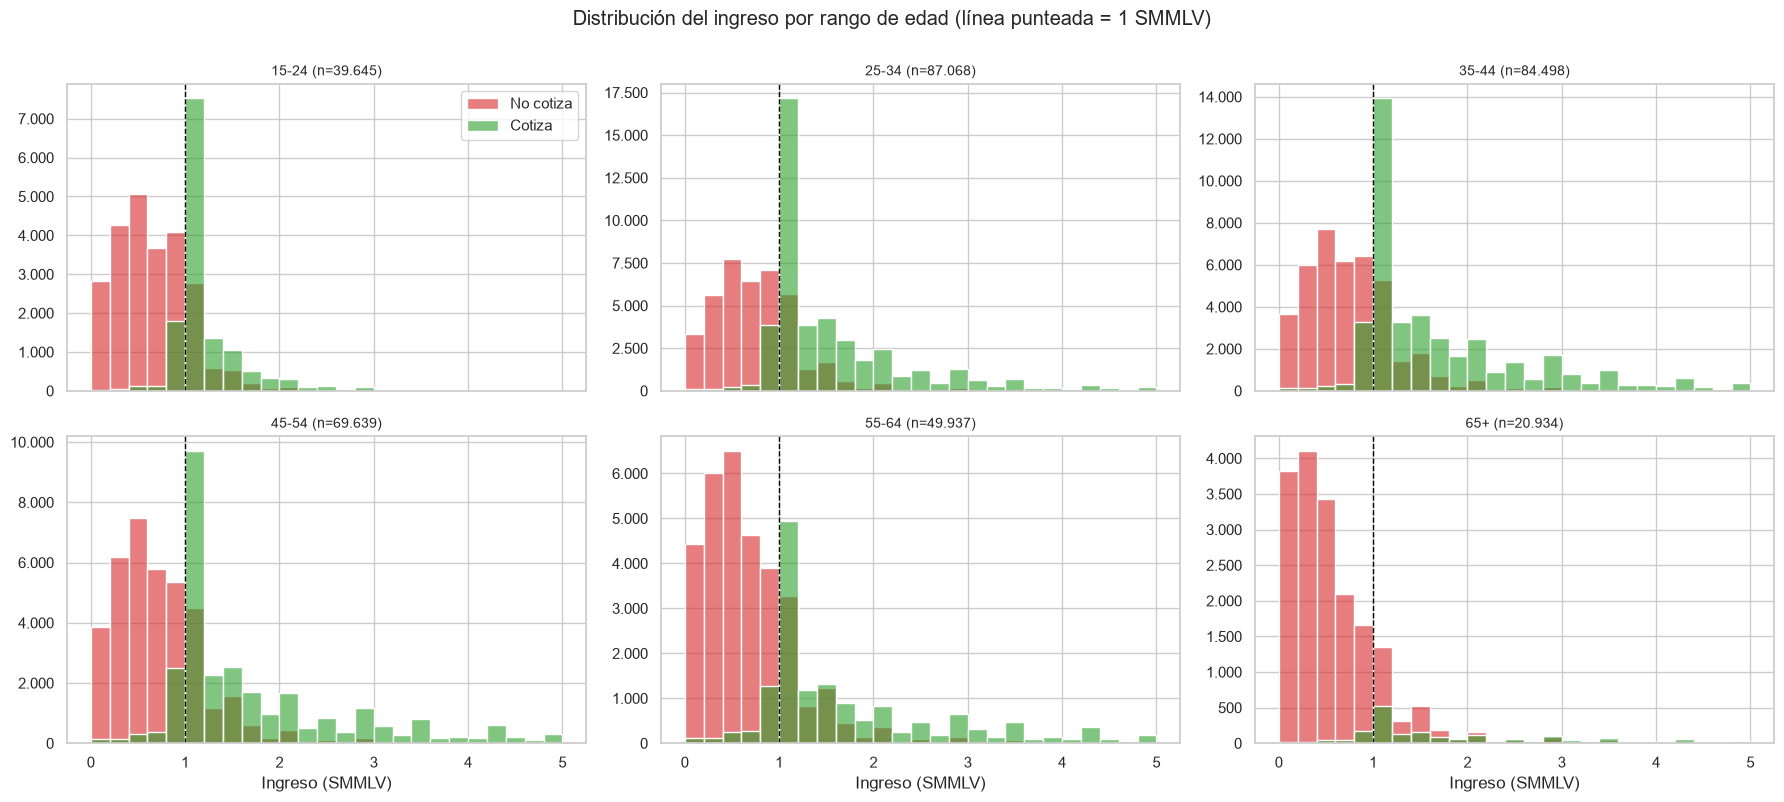

,n,cotiza,contrato,gana_1_smmlv,mediana_ingreso_smmlv,mediana_no_cotiza,mediana_cotiza
edad,,,,,,,
15-24,39645,34.8,70.9,42.1,0.91,0.60,1.00
25-34,87068,51.8,70.6,59.3,1.00,0.70,1.26
35-44,84498,50.5,64.7,58.9,1.00,0.70,1.35
45-54,69639,44.0,56.6,52.8,1.00,0.63,1.33
55-64,49937,33.1,45.9,43.4,0.84,0.56,1.36
65+,20934,10.2,27.5,23.6,0.53,0.42,1.40


In [27]:
histogramas_ingreso(rango_edad, 'rango de edad', columnas=3)
resumen_ingreso(rango_edad)

El ingreso sigue la misma forma de montaña que la cotización. El porcentaje que gana 1 SMMLV o más es de 42 % a los 15–24 años, sube a 59 % entre los 25 y 44, y baja a 53 % en 45–54, 43 % en 55–64 y 24 % desde los 65; la mediana de ingreso cae de 1,0 SMMLV a 0,84 en 55–64 y 0,53 en los de 65 o más. El contrato baja de forma más continua, de 71 % en los jóvenes a 27 % en los de 65 o más. Entre quienes no cotizan la mediana va de 0,60–0,70 SMMLV hasta los 44 años a 0,42 en los de 65 o más, mientras que la de los cotizantes sube de 1,0 en los jóvenes a 1,4 en los de 65 o más. La brecha de ingreso entre cotizar y no cotizar se ensancha con la edad. Los ingresos mayores a 5 SMMLV quedan fuera del rango graficado.

**Sexo y rango de edad combinados, según cotice o no.** Se compara dentro de cada sexo cómo cambia la cotización con la edad.

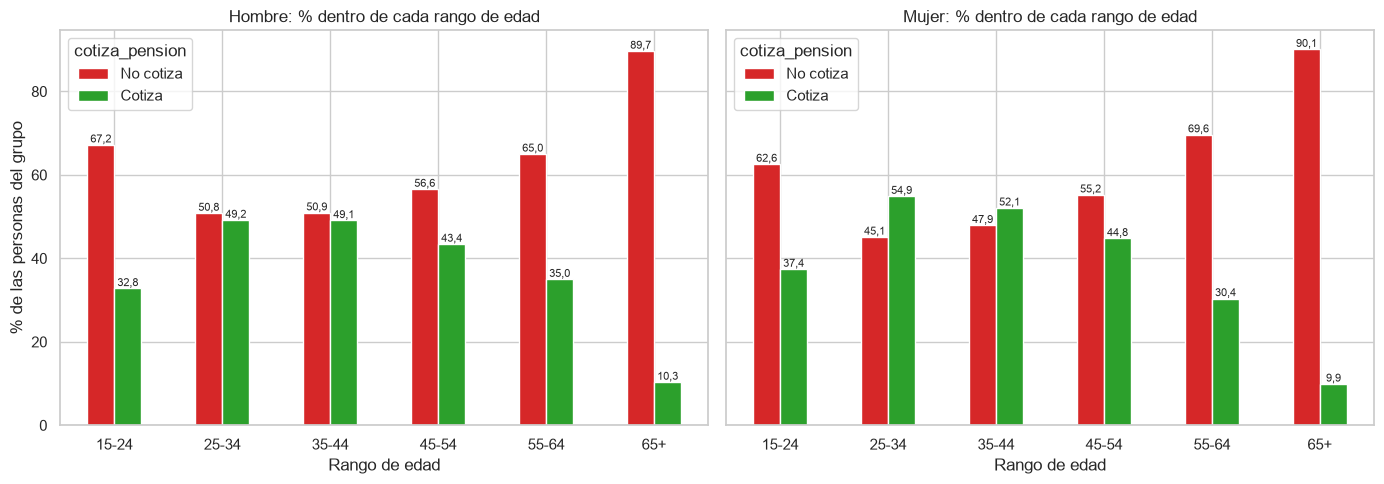

Frecuencia absoluta               % dentro del grupo         \
cotiza_pension           No cotiza Cotiza  Total          No cotiza Cotiza   
sexo   edad                                                                  
Hombre 15-24                 15329   7478  22807               67.2   32.8   
       25-34                 23716  22939  46655               50.8   49.2   
       35-44                 22567  21747  44314               50.9   49.1   
       45-54                 21306  16350  37656               56.6   43.4   
       55-64                 19403  10441  29844               65.0   35.0   
       65+                   12457   1436  13893               89.7   10.3   
Mujer  15-24                 10539   6299  16838               62.6   37.4   
       25-34                 18233  22180  40413               45.1   54.9   
       35-44                 19250  20934  40184               47.9   52.1   
       45-54                 17662  14321  31983               55.2   44.8   
       55-64                 13990   6103  20093               69.6   30.4   
       65+                    6344    697   7041               90.1    9.9   

               % del total         
cotiza_pension   No cotiza Cotiza  
sexo   edad                        
Hombre 15-24           4.4    2.1  
       25-34           6.7    6.5  
       35-44           6.4    6.2  
       45-54           6.1    4.6  
       55-64           5.5    3.0  
       65+             3.5    0.4  
Mujer  15-24           3.0    1.8  
       25-34           5.2    6.3  
       35-44           5.5    6.0  
       45-54           5.0    4.1  
       55-64           4.0    1.7  
       65+             1.8    0.2

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, sexo in zip(axes, ['Hombre', 'Mujer']):
    sub = df[df['sexo'] == sexo]
    rel = (pd.crosstab(rango_edad.loc[sub.index], sub['cotiza_pension'], normalize='index') * 100).rename(columns=etiquetas)
    barras_agrupadas(rel, ax, colores)
    for cont in ax.containers:
        ax.bar_label(cont, fmt=coma, fontsize=8)
    ax.set_title(f'{sexo}: % dentro de cada rango de edad')
    ax.set_xlabel('Rango de edad')
    ax.tick_params(axis='x', rotation=0)
axes[0].set_ylabel('% de las personas del grupo')
plt.tight_layout()
plt.show()

tabla_frecuencias([df['sexo'], rango_edad])

Hasta los 54 años las mujeres cotizan más que los hombres en todos los rangos: 37 % frente a 33 % en 15–24, 55 % frente a 49 % en 25–34, 52 % frente a 49 % en 35–44 y 45 % frente a 43 % en 45–54. La relación se invierte en 55–64 años (30 % de las mujeres frente a 35 % de los hombres) y desaparece desde los 65 (10 % en ambos). Es decir, la ventaja de las mujeres se concentra en las edades de mayor actividad laboral y se pierde cerca de la edad de pensión. En ambos sexos el patrón por edad es el mismo: máximo entre 25 y 44 años y caída fuerte después de los 54.

**Frecuencia absoluta y relativa por nivel educativo, según cotice o no.**

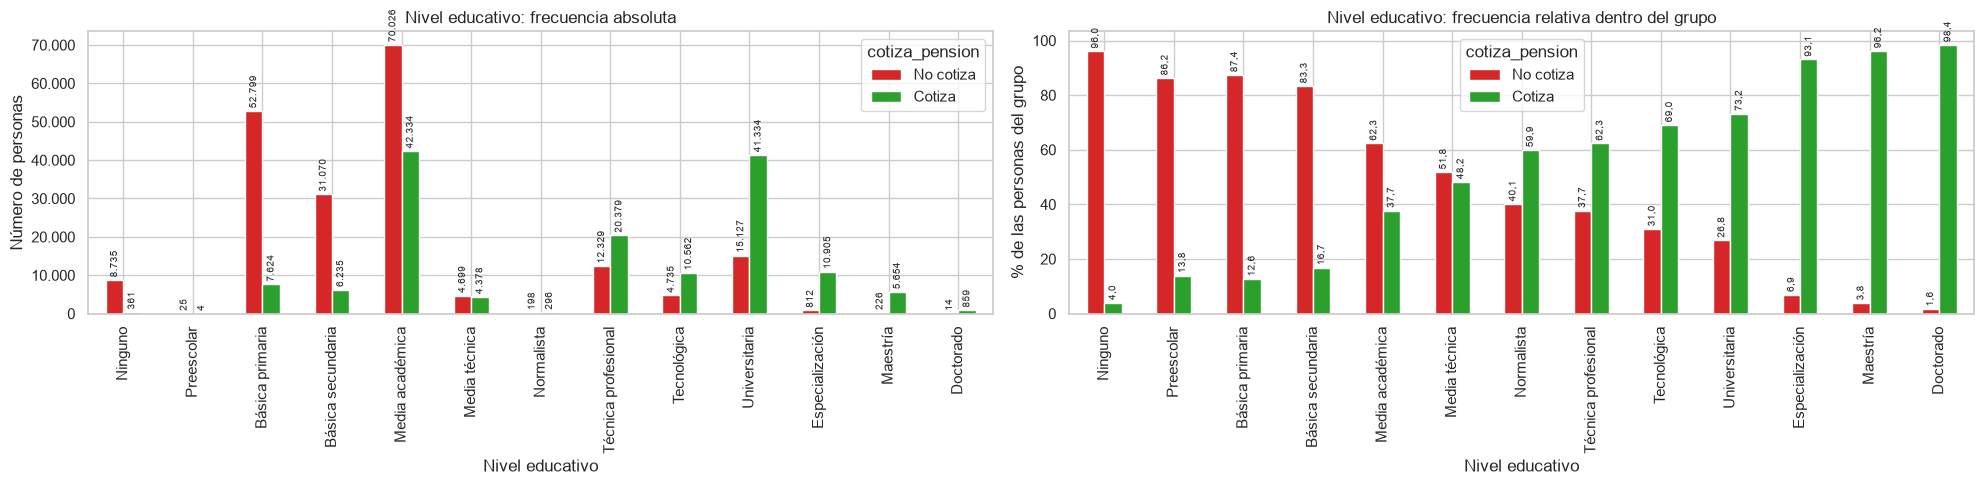

Frecuencia absoluta                % dentro del grupo  \
cotiza_pension                No cotiza Cotiza   Total          No cotiza   
nivel_educativo                                                             
Ninguno                            8735    361    9096               96.0   
Preescolar                           25      4      29               86.2   
Básica primaria                   52799   7624   60423               87.4   
Básica secundaria                 31070   6235   37305               83.3   
Media académica                   70026  42334  112360               62.3   
Media técnica                      4699   4378    9077               51.8   
Normalista                          198    296     494               40.1   
Técnica profesional               12329  20379   32708               37.7   
Tecnológica                        4735  10562   15297               31.0   
Universitaria                     15127  41334   56461               26.8   
Especialización                     812  10905   11717                6.9   
Maestría                            226   5654    5880                3.8   
Doctorado                            14    859     873                1.6   

                           % del total         
cotiza_pension      Cotiza   No cotiza Cotiza  
nivel_educativo                                
Ninguno                4.0         2.5    0.1  
Preescolar            13.8         0.0    0.0  
Básica primaria       12.6        15.0    2.2  
Básica secundaria     16.7         8.8    1.8  
Media académica       37.7        19.9   12.0  
Media técnica         48.2         1.3    1.2  
Normalista            59.9         0.1    0.1  
Técnica profesional   62.3         3.5    5.8  
Tecnológica           69.0         1.3    3.0  
Universitaria         73.2         4.3   11.8  
Especialización       93.1         0.2    3.1  
Maestría              96.2         0.1    1.6  
Doctorado             98.4         0.0    0.2

In [29]:
nivel_ord = pd.Series(pd.Categorical(df['nivel_educativo'].where(df['nivel_educativo'].isin(orden_edu)),
                                     categories=orden_edu, ordered=True),
                      index=df.index, name='nivel_educativo')

graficar_frecuencias(nivel_ord, 'Nivel educativo', ancho=20, rotacion=90, tam_etiqueta=7, rot_etiqueta=90)
tabla_frecuencias(nivel_ord)

La educación es la variable que más separa. El grupo más grande es media académica (112.360 personas, 32 % del total), con 38 % de cotización, seguido de básica primaria (60.423) y universitaria (56.461). En términos absolutos, el mayor número de no cotizantes está en media académica (70.026) y básica primaria (52.799). En términos relativos, los niveles bajos casi no cotizan (4 % sin estudios, 13 % en primaria, 17 % en secundaria) y desde especialización cotiza más de 90 %. Los grupos pequeños (preescolar, normalista, doctorado) hay que leerlos con cuidado porque tienen pocos casos.

## 8. EDA complementario

Las secciones anteriores miran la cotización según edad, sexo, educación, posición ocupacional, tamaño de empresa y zona. Antes de modelar falta revisar:

1. La calidad de los datos: duplicados, ingresos en cero y nulos.
2. Las variables numéricas y sus valores atípicos.
3. Las variables que no se habían explorado: departamento, estado civil, parentesco, estrato, lugar de trabajo y rama de actividad.
4. Qué mide realmente `tiene_contrato`.
5. Quiénes ganan 1 SMMLV o más y aun así no cotizan.
6. Qué tan fuerte es cada variable frente al objetivo y cuáles se repiten entre sí.
7. Si los meses de entrenamiento (enero–septiembre) y de prueba (octubre–diciembre) se parecen.
8. Si las cifras cambian al usar el factor de expansión (muestra frente a población).
9. Quiénes son los asalariados que ganan 1 SMMLV o más y no cotizan, el grupo donde el modelo falla más.

### 8.1 Calidad de los datos

**Duplicados y personas repetidas.** En la GEIH una persona se identifica con vivienda, secuencia, hogar y orden. Se revisa si hay filas repetidas y si una misma persona aparece en más de un mes. Si eso pasara, el split temporal pondría a la misma persona en entrenamiento y en prueba.

In [30]:
import numpy as np

llave = ['directorio', 'secuencia_p', 'hogar', 'orden']
print('Filas duplicadas (misma persona y mes):', df.duplicated(llave + ['mes']).sum())
meses_por_persona = df.groupby(llave)['mes'].nunique()
print('Personas que aparecen en más de un mes:', (meses_por_persona > 1).sum())

Filas duplicadas (misma persona y mes): 0
Personas que aparecen en más de un mes: 0


No hay filas duplicadas y ninguna persona aparece en dos meses, porque cada mes la GEIH encuesta hogares distintos. Por eso el split por meses no mezcla a la misma persona entre entrenamiento y prueba.

**Ingreso en cero y nulos de ingreso.** Se revisa quiénes reportan ingreso 0 y quiénes no tienen ingreso, según su posición ocupacional.

In [31]:
print('Ingreso igual a 0:', (df['ingreso'] == 0).sum())
print(df.loc[df['ingreso'] == 0, 'posicion_ocupacional'].value_counts())
print()
print('Ingreso nulo:', df['ingreso'].isna().sum())
print(df.loc[df['ingreso'].isna(), 'posicion_ocupacional'].value_counts())

Ingreso igual a 0: 2507
posicion_ocupacional
Cuenta propia                  2291
Patrón o empleador              197
Empleado empresa particular      13
Otro                              3
Empleado del gobierno             1
Empleado doméstico                1
Jornalero o peón                  1
Name: count, dtype: int64

Ingreso nulo: 7916
posicion_ocupacional
Familiar sin remuneración      5660
Cuenta propia                  1017
Empleado empresa particular     655
Patrón o empleador              329
Empleado del gobierno           236
Empleado doméstico               12
Jornalero o peón                  6
Otro                              1
Name: count, dtype: int64


Hay **2.507 ocupados con ingreso 0**, casi todos cuenta propia (2.291) y patrones (197). Lo más probable es que sean negocios que ese mes no tuvieron ganancia, así que el valor es posible y se deja.

Los **7.916 nulos de ingreso** no son al azar:
- 5.660 son familiares sin remuneración, que por definición no reciben pago.
- El resto son personas que no respondieron: 1.017 cuenta propia, 655 empleados de empresa particular, 329 patrones y 236 empleados del gobierno, entre otros.

**Para el modelo:** el nulo no se puede borrar sin sesgar la muestra. Lo recomendable es imputarlo dentro del pipeline, con valores calculados solo en entrenamiento (por ejemplo, la mediana por posición ocupacional), y agregar una marca de "ingreso no reportado".

### 8.2 Variables numéricas y valores atípicos

Distribución de edad, horas por semana, meses en la empresa e ingreso en SMMLV, separando a quienes cotizan de quienes no. Para que los gráficos se lean bien se recortan en el percentil 99; los datos no se modifican.

      edad  horas_semana  meses_en_empresa  ingreso_smmlv
0.01  18.0           8.0               0.0           0.03
0.05  21.0          20.0               2.0           0.14
0.25  30.0          40.0              12.0           0.56
0.50  40.0          46.0              36.0           1.00
0.75  52.0          48.0             120.0           1.33
0.95  66.0          60.0             340.0           3.30
0.99  75.0          84.0             480.0           6.39


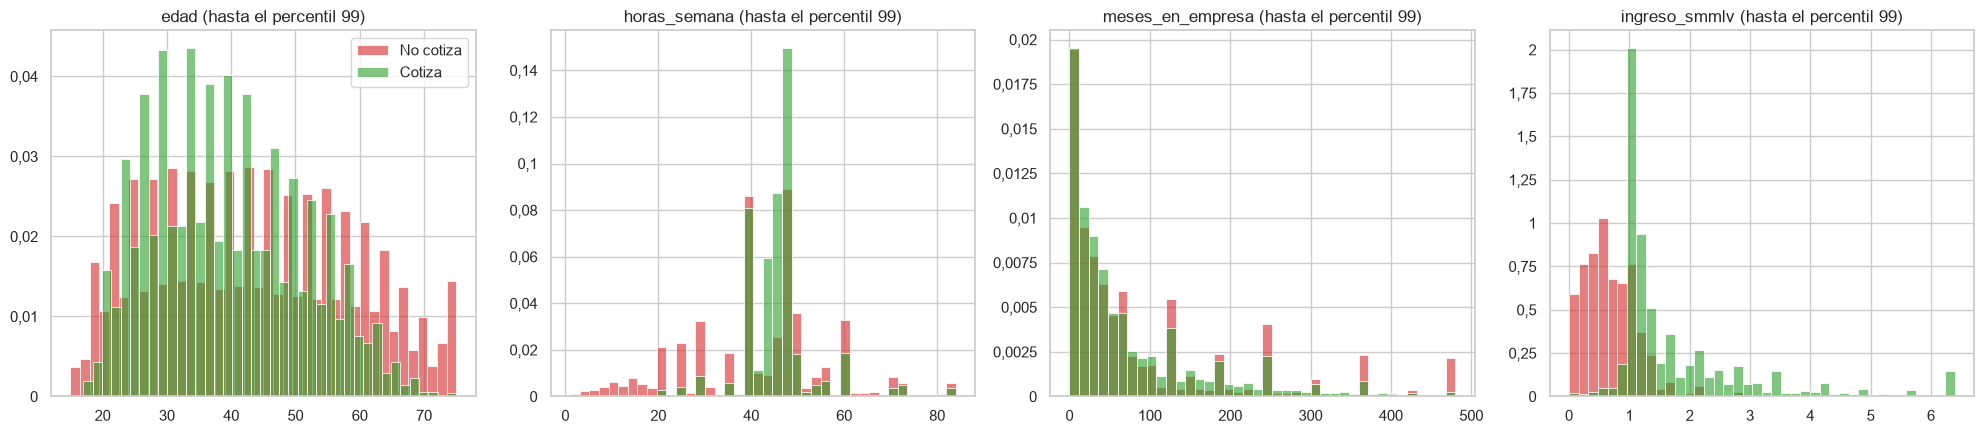

Mediana según cotice o no:
                edad  horas_semana  meses_en_empresa  ingreso_smmlv
cotiza_pension                                                     
No cotiza       42.0          44.0              36.0       0.632244
Cotiza          38.0          46.0              36.0       1.264489


In [32]:
numericas = ['edad', 'horas_semana', 'meses_en_empresa', 'ingreso_smmlv']
print(df[numericas].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axes, numericas):
    tope = df[col].quantile(0.99)
    for valor, color in zip([0, 1], colores):
        datos = df.loc[df['cotiza_pension'] == valor, col].dropna()
        sns.histplot(datos.clip(upper=tope), bins=40, stat='density', alpha=0.6, color=color, label=etiquetas[valor], ax=ax)
    ax.set_title(f'{col} (hasta el percentil 99)')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.xaxis.set_major_formatter(eje_decimal)
    ax.yaxis.set_major_formatter(eje_decimal)
axes[0].legend()
plt.tight_layout()
plt.show()

print('Mediana según cotice o no:')
print(df.groupby('cotiza_pension')[numericas].median().rename(index=etiquetas))

In [33]:
print('Horas por semana mayores a 84 (más de 12 horas diarias los 7 días):', (df['horas_semana'] > 84).sum())
print('Meses en la empresa mayores a 600 (50 años):', (df['meses_en_empresa'] > 600).sum())
print('Meses en la empresa mayores que (edad - 10) x 12:', (df['meses_en_empresa'] > (df['edad'] - 10) * 12).sum())
print('Ingreso mayor a 20 SMMLV:', (df['ingreso_smmlv'] > 20).sum())

Horas por semana mayores a 84 (más de 12 horas diarias los 7 días): 1393
Meses en la empresa mayores a 600 (50 años): 507
Meses en la empresa mayores que (edad - 10) x 12: 36
Ingreso mayor a 20 SMMLV: 253


**El ingreso es la variable numérica que más separa.** La mediana de quienes cotizan es 1,26 SMMLV, el doble que la de quienes no cotizan (0,63). Las demás separan poco:
- Edad: mediana de 38 años en quienes cotizan y 42 en quienes no. La relación tiene forma de montaña (sección 7), así que una sola recta no la captura.
- Horas por semana: 46 frente a 44.
- Meses en la empresa: la misma mediana (36 meses) en los dos grupos.

**Colas largas y atípicos:**
- Ingreso: el percentil 99 es 6,4 SMMLV y el máximo 72 SMMLV. Hay 253 personas con más de 20 SMMLV.
- Horas: 1.393 personas (0,4 %) reportan más de 84 horas a la semana, con un máximo de 130.
- Meses en la empresa: 507 personas reportan más de 50 años en la misma empresa. Además, 36 casos son incoherentes porque llevan más tiempo en la empresa del que permite su edad (más de `(edad - 10) × 12` meses).

**Decisión:** no se borran. Son pocos y casi todos son posibles. Para la regresión logística conviene usar `log(1 + ingreso_smmlv)` y recortar horas y meses en el percentil 99, calculado **solo con entrenamiento**. Los 36 casos incoherentes se pueden recortar al máximo posible según la edad. El boosting no necesita estas transformaciones.

### 8.3 Variables que faltaban por revisar

**% que cotiza por departamento.** La línea punteada es el promedio de todos los ocupados.

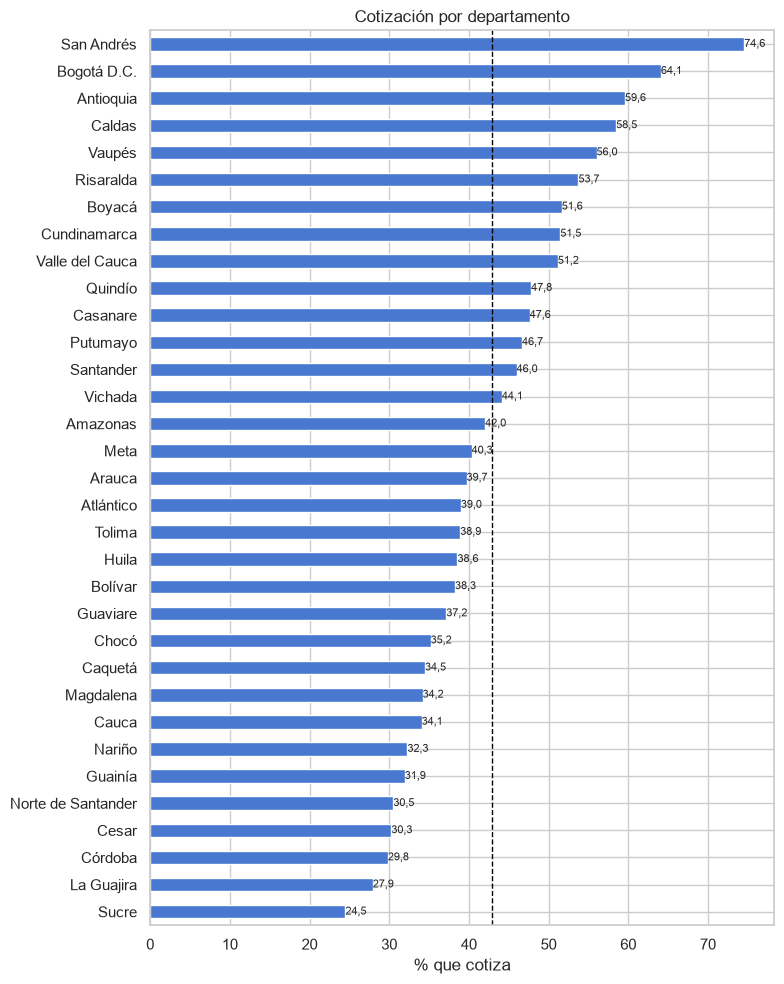

In [34]:
por_depto = (df.groupby('departamento')['cotiza_pension'].mean() * 100).sort_values()
plt.figure(figsize=(8, 10))
ax = barras(por_depto, horizontal=True)
ax.axvline(df['cotiza_pension'].mean() * 100, color='black', linestyle='--', linewidth=1)
ax.bar_label(ax.containers[0], fmt=coma, fontsize=8)
plt.xlabel('% que cotiza')
plt.ylabel('')
plt.title('Cotización por departamento')
plt.tight_layout()
plt.show()

Hay mucha diferencia entre regiones:
- **Los más bajos son del Caribe y de frontera:** Sucre (24,5 %), La Guajira (27,9 %), Córdoba (29,8 %), Cesar (30,3 %) y Norte de Santander (30,5 %).
- **Los más altos:** San Andrés (74,6 %), Bogotá (64,1 %), Antioquia (59,6 %) y Caldas (58,5 %).

Parte de esta diferencia se explica por la mezcla urbano/rural y por la estructura del empleo de cada departamento. El departamento puede seguir aportando algo propio, pero eso lo dirá el modelo.

Los departamentos más nuevos (Guainía, Vichada, Putumayo, Arauca, Amazonas) tienen menos de 2.000 personas en la muestra, así que sus porcentajes son menos estables. Con 33 categorías se puede usar one-hot sin problema.

**Estado civil, parentesco y estrato.** Número de personas y porcentaje que cotiza en cada categoría. En estrato se dejan visibles los valores 0, 9 y nulo, que no tienen significado confirmado.

In [35]:
def tasa_por(col, orden=None):
    """Número de personas y % que cotiza en cada categoría de `col` (los nulos se muestran)."""
    t = df.groupby(col, dropna=False)['cotiza_pension'].agg(n='size', cotiza='mean')
    t['cotiza'] = (t['cotiza'] * 100).round(1)
    return t.reindex(orden) if orden is not None else t.sort_values('n', ascending=False)


print(tasa_por('estado_civil'), end='\n\n')
print(tasa_por('parentesco_jefe'), end='\n\n')
print(tasa_por('estrato', orden=[1, 2, 3, 4, 5, 6, 0, 9, np.nan]))

                                  n  cotiza
estado_civil                               
Unión libre 2 años o más     113619    39.5
Soltero(a)                    98726    46.9
Casado(a)                     65448    51.8
Separado(a) o divorciado(a)   57643    35.3
Unión libre menos de 2 años    8933    45.5
Viudo(a)                       7352    18.3

                         n  cotiza
parentesco_jefe                   
Jefe(a) del hogar   185028    42.2
Pareja del jefe(a)   71449    43.5
Hijo(a)              65716    46.6
Otro                 29528    37.6

              n  cotiza
estrato                
1.0      130254    27.5
2.0      115852    45.5
3.0       69350    59.5
4.0       17697    73.3
5.0        5894    79.9
6.0        2743    82.0
0.0        6195    11.8
9.0        2234    11.5
NaN        1502     8.9


**Estado civil.** Separa algo. Los viudos(as) cotizan muy poco (18,3 %), pero sobre todo porque son mayores: la edad promedio de este grupo es de 60 años. Los casados(as) cotizan 51,8 % y quienes viven en unión libre de 2 años o más, 39,5 %.

**Parentesco.** Separa poco, igual que el sexo: todos los grupos están entre 37,6 % y 46,6 %.

**Estrato.** Muestra un gradiente claro: de 27,5 % en estrato 1 a 82 % en estrato 6. Los valores sin significado confirmado se comportan igual entre sí:
- Código 0: 6.195 personas, 11,8 % cotiza.
- Código 9: 2.234 personas, 11,5 %.
- Nulos: 1.502 personas, 8,9 %.

Los tres cotizan menos que el estrato 1, así que es razonable agruparlos en una categoría "Sin estrato / no informa" (9.931 personas) en lugar de tratarlos como números. El estrato es una variable de la vivienda y del nivel socioeconómico del hogar, no del empleo. Por eso aporta información distinta a las variables laborales (ver 8.6).

**Lugar de trabajo y rama de actividad.** `lugar_trabajo` sigue con su código original porque no se pudo confirmar el significado de cada valor. En `rama_2d` se muestran las 15 ramas con más ocupados, con su nombre según la CIIU Rev. 4 a dos dígitos.

In [36]:
print(tasa_por('lugar_trabajo'))

                    n  cotiza
lugar_trabajo                
7.0            169174    68.0
1.0             43765    20.1
2.0             39335     9.5
8.0             32162    13.6
4.0             27096    30.7
6.0             18975    15.5
9.0             10686    36.5
5.0              7819    38.4
3.0              1200     8.0
10.0             1039    47.0
11.0              470    47.2


Ramas distintas: 88
Las 15 ramas más grandes suman 73% de los ocupados


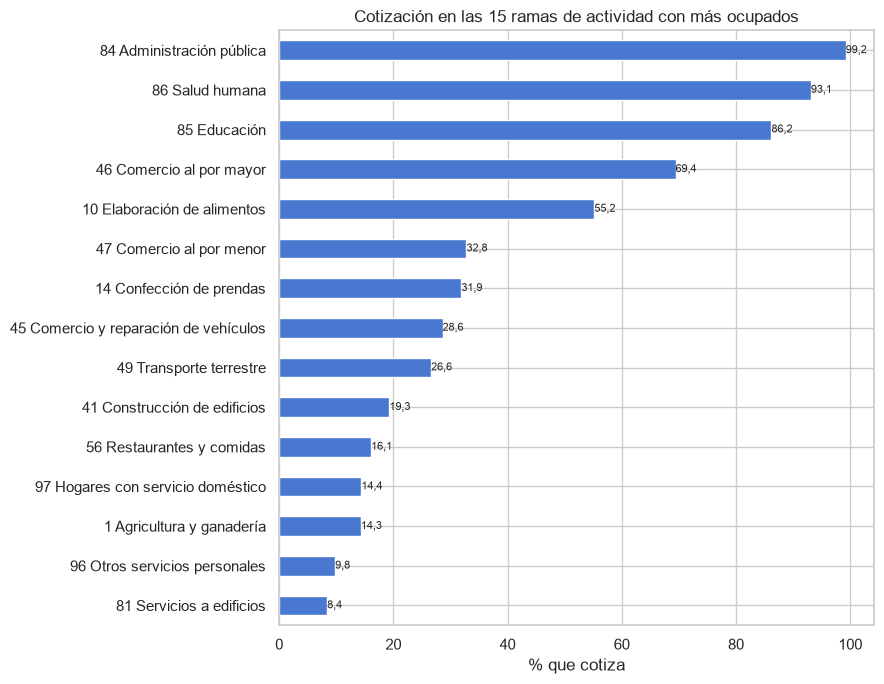

In [37]:
nombres_rama = {
    47: 'Comercio al por menor', 1: 'Agricultura y ganadería', 56: 'Restaurantes y comidas',
    49: 'Transporte terrestre', 85: 'Educación', 41: 'Construcción de edificios',
    84: 'Administración pública', 86: 'Salud humana', 97: 'Hogares con servicio doméstico',
    96: 'Otros servicios personales', 81: 'Servicios a edificios', 45: 'Comercio y reparación de vehículos',
    10: 'Elaboración de alimentos', 46: 'Comercio al por mayor', 14: 'Confección de prendas',
}

print('Ramas distintas:', df['rama_2d'].nunique())
top_ramas = tasa_por('rama_2d').head(15)
top_ramas.index = [f'{int(c)} {nombres_rama.get(int(c), "")}' for c in top_ramas.index]
print('Las 15 ramas más grandes suman', f"{top_ramas['n'].sum() / len(df):.0%}", 'de los ocupados')

plt.figure(figsize=(9, 7))
ax = barras(top_ramas['cotiza'].sort_values(), horizontal=True)
ax.bar_label(ax.containers[0], fmt=coma, fontsize=8)
plt.xlabel('% que cotiza')
plt.title('Cotización en las 15 ramas de actividad con más ocupados')
plt.tight_layout()
plt.show()

**Lugar de trabajo.** El código 7 reúne casi la mitad de los ocupados (169.174) y cotiza 68 %. Los demás códigos están entre 8 % y 47 %. Separa bastante, pero hasta confirmar el significado de cada código con el diccionario oficial no se puede interpretar. También va muy de la mano con la zona y con la rama de actividad (ver 8.6).

**Rama de actividad.** Hay 88 ramas y las 15 más grandes reúnen el 73 % de los ocupados. Las diferencias son enormes:
- **Ramas donde casi todos cotizan:** administración pública (99,2 %), salud (93,1 %) y educación (86,2 %), donde predomina el empleo público o formal.
- **Ramas con muy baja cotización:** servicios a edificios (8,4 %), otros servicios personales como peluquerías (9,8 %), agricultura (14,3 %), servicio doméstico (14,4 %), restaurantes (16,1 %) y construcción (19,3 %).
- **Comercio al por menor:** es la rama más grande (50.677 ocupados) y solo cotiza el 32,8 %.

**Para el modelo:** con 88 categorías, varias muy pequeñas, conviene agrupar las ramas con pocos casos en entrenamiento en "Otra". Otra opción es pasar a las 21 secciones CIIU.

### 8.4 ¿Qué mide `tiene_contrato`?

Se cruza el contrato con la posición ocupacional, primero en los datos limpios y luego en el archivo crudo (P6430 = posición, P6440 = contrato), para descartar que el patrón venga de la limpieza.

In [38]:
print(pd.crosstab(df['posicion_ocupacional'], df['tiene_contrato'].map({1: 'Con contrato', 0: 'Sin contrato'})))
print()
print((df.groupby('tiene_contrato')['cotiza_pension'].mean() * 100).round(1).rename(index={1: 'Con contrato', 0: 'Sin contrato'}))

tiene_contrato               Con contrato  Sin contrato
posicion_ocupacional                                   
Cuenta propia                       25306        126104
Empleado del gobierno               17431             0
Empleado doméstico                  11865             0
Empleado empresa particular        149085             0
Familiar sin remuneración               0          5660
Jornalero o peón                     8390             0
Otro                                  135            19
Patrón o empleador                    124          7602

tiene_contrato
Sin contrato     8.1
Con contrato    65.8
Name: cotiza_pension, dtype: float64


In [39]:
crudo = pd.read_csv(ruta, usecols=['P6430', 'P6440'])
pd.crosstab(crudo['P6430'], crudo['P6440'])

P6440,1.0,2.0
P6430,,
1.0,150485,0
2.0,18499,0
3.0,12040,0
4.0,25863,128595
5.0,129,8005
6.0,0,5830
7.0,8429,0
8.0,135,19


**Hallazgo importante: `tiene_contrato` no mide lo que su nombre dice.**
- Todos los asalariados aparecen con contrato y ninguno sin contrato: empleados de empresa particular (149.085), del gobierno, domésticos y jornaleros.
- Solo los independientes tienen valores 0: cuenta propia (17 % con contrato), patrones (2 %) y familiares sin remuneración (0 %).
- El archivo crudo trae exactamente el mismo patrón en P6440, así que **no es un error de la limpieza**.

En Colombia una parte importante de los asalariados trabaja sin contrato, así que este resultado no describe la realidad. Lo más probable es que la pregunta no se haga igual a todos o que la fuente rellene el valor para los asalariados.

**Consecuencias:**
1. En la práctica, `tiene_contrato` casi equivale a "es asalariado". Repite la posición ocupacional (V de Cramér de 0,86 en 8.6) y no agrega una dimensión nueva de formalidad.
2. La gran diferencia de cotización (65,8 % con contrato frente a 8,1 % sin contrato) es, sobre todo, la diferencia entre asalariados e independientes.
3. La sección 7 dice que, entre quienes no cotizan, el contrato no cambia con la educación. Ese resultado se debe leer como "la proporción de asalariados no cambia con la educación".

**Qué se hizo:** en la selección de modelos (notebook 02) se entrenaron los 7 modelos con y sin `tiene_contrato`, y la variable no mejoró ninguno. Por eso sale del modelo. Queda pendiente confirmar en el diccionario de la GEIH 2025 del DANE a quién se le hace P6440.

### 8.5 Quienes ganan 1 SMMLV o más y no cotizan

Este es el grupo de interés para política pública: tienen ingreso para cotizar y no lo hacen. Se cuenta cuántos son y en qué posiciones ocupacionales, tamaños de empresa y zonas están.

In [40]:
gana = df[df['gana_1_smmlv_o_mas'] == 1]
gana_no_cotiza = gana[gana['cotiza_pension'] == 0]
print(f'Ganan 1 SMMLV o más: {len(gana):,}')
print(f'De ellos no cotizan: {len(gana_no_cotiza):,} ({len(gana_no_cotiza) / len(gana):.1%})')
peso_no = gana_no_cotiza['factor_expansion'].sum() / gana['factor_expansion'].sum()
print(f'Con factor de expansión: {peso_no:.1%}, unos {gana_no_cotiza["factor_expansion"].sum() / 12:,.0f} trabajadores en un mes promedio')

for col in ['posicion_ocupacional', 'tamano_empresa', 'zona']:
    print()
    print((gana_no_cotiza[col].value_counts(normalize=True) * 100).round(1).head(5))

Ganan 1 SMMLV o más: 177,622
De ellos no cotizan: 44,903 (25.3%)
Con factor de expansión: 24.8%, unos 2,984,542 trabajadores en un mes promedio

posicion_ocupacional
Cuenta propia                  53.3
Empleado empresa particular    32.8
Patrón o empleador              7.1
Jornalero o peón                3.4
Empleado doméstico              3.4
Name: proportion, dtype: float64

tamano_empresa
Trabaja solo    45.1
2 a 3           24.2
4 a 5           13.1
6 a 10           8.5
11 a 19          3.9
Name: proportion, dtype: float64

zona
Urbano    88.3
Rural     11.7
Name: proportion, dtype: float64


**Uno de cada cuatro ocupados que gana 1 SMMLV o más no cotiza a pensión.** Son 44.903 de 177.622 en la muestra (25,3 %; 24,8 % con factor de expansión). Eso equivale a unos **3 millones de trabajadores en un mes promedio** que tienen ingreso para cotizar y no lo hacen.

El perfil es claro:
- **Tipo de trabajo:** 53 % son cuenta propia, 33 % empleados de empresa particular y 7 % patrones.
- **Tamaño de la empresa:** 45 % trabajan solos y 91 % están en negocios de 10 personas o menos.
- **Zona:** 88 % son urbanos.

No es un problema rural ni de bajos ingresos. Es un problema de **independientes y microempresas urbanas**. Para fondos de pensiones, Colpensiones o la UGPP, este es el grupo donde un modelo de probabilidad sería más útil para focalizar campañas de afiliación o fiscalización.

### 8.6 Fuerza de cada variable frente al objetivo

Para las variables categóricas se usa la **V de Cramér**: va de 0 (no hay relación) a 1 (la categoría define el resultado). Para las numéricas se usa la **correlación de Spearman** con `cotiza_pension`. Las dos medidas no se comparan entre sí; sirven para ordenar las variables dentro de cada grupo. Esto es una mirada descriptiva sobre todo el año; la selección final de variables se hace con los datos de entrenamiento.

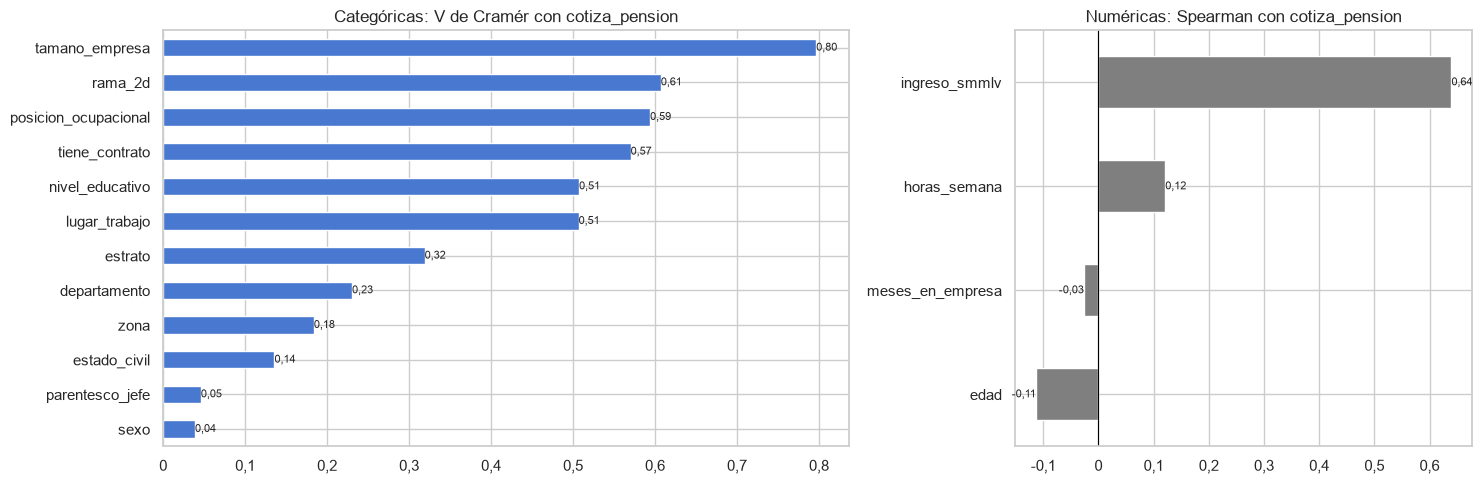

In [41]:
def v_cramer(a, b):
    """V de Cramér entre dos variables categóricas (0 = sin relación, 1 = relación total)."""
    tabla = pd.crosstab(a, b).to_numpy()
    n = tabla.sum()
    esperado = tabla.sum(axis=1, keepdims=True) * tabla.sum(axis=0, keepdims=True) / n
    chi2 = ((tabla - esperado) ** 2 / esperado).sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))


categoricas = ['departamento', 'zona', 'sexo', 'parentesco_jefe', 'estado_civil', 'nivel_educativo',
               'posicion_ocupacional', 'tamano_empresa', 'lugar_trabajo', 'tiene_contrato', 'rama_2d', 'estrato']
como_texto = df[categoricas].astype(str)  # los nulos quedan como 'nan', una categoría más

v = pd.Series({c: v_cramer(como_texto[c], df['cotiza_pension']) for c in categoricas}).sort_values()
spearman = df[numericas].corrwith(df['cotiza_pension'], method='spearman').sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [3, 2]})
barras(v, horizontal=True, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt=lambda v: coma(v, 2), fontsize=8)
axes[0].set_title('Categóricas: V de Cramér con cotiza_pension')
barras(spearman, horizontal=True, ax=axes[1], color='tab:gray')
axes[1].bar_label(axes[1].containers[0], fmt=lambda v: coma(v, 2), fontsize=8)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Numéricas: Spearman con cotiza_pension')
for ax in axes:
    ax.xaxis.set_major_formatter(eje_decimal)
plt.tight_layout()
plt.show()

**Categóricas.** Las variables del empleo son las más fuertes:
- Tamaño de empresa: 0,80.
- Rama de actividad: 0,61.
- Posición ocupacional: 0,59.
- `tiene_contrato`: 0,57.
- Nivel educativo y lugar de trabajo: 0,51 cada una.

Le siguen el estrato (0,32), el departamento (0,23) y la zona (0,18). Estado civil (0,14), parentesco (0,05) y sexo (0,04) casi no separan por sí solos.

**Numéricas.** El ingreso en SMMLV tiene una correlación de 0,64 con cotizar. Las demás son débiles: horas (0,12), edad (−0,11) y meses en la empresa (−0,03).

**Cuidado con la edad:** su relación con cotizar tiene forma de montaña, así que una correlación cercana a 0 no significa que no importe. En la regresión logística conviene usar tramos de edad o agregar edad². Además, la V de Cramér sale algo más alta en variables con muchas categorías, como la rama (88), así que el orden es una guía y no una selección.

**Variables que se repiten entre sí.** Si dos variables dicen casi lo mismo, el modelo no gana mucho con tener ambas y los coeficientes de la regresión logística se vuelven inestables. Se calcula la V de Cramér entre las variables laborales y socioeconómicas, y la correlación de Spearman entre las numéricas.

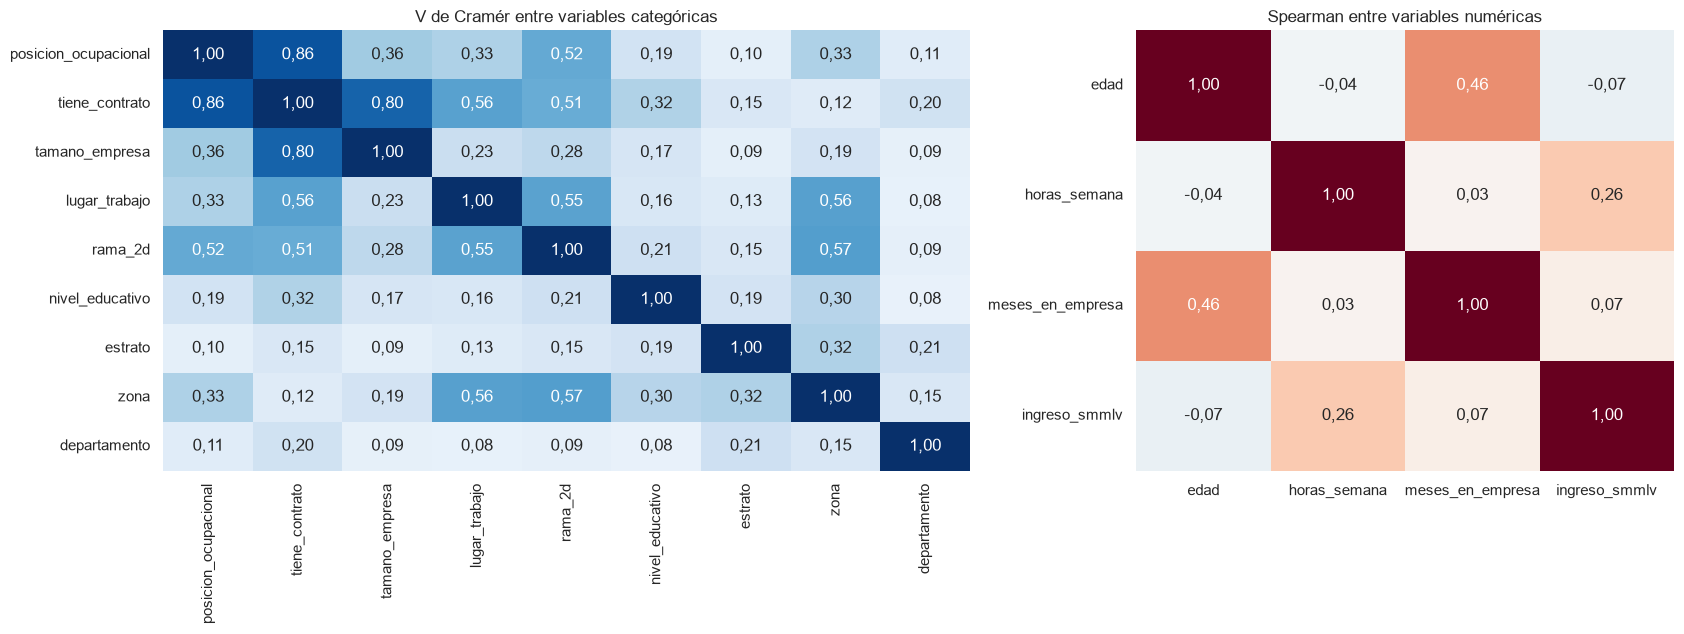

In [42]:
grupo = ['posicion_ocupacional', 'tiene_contrato', 'tamano_empresa', 'lugar_trabajo', 'rama_2d',
         'nivel_educativo', 'estrato', 'zona', 'departamento']
matriz = pd.DataFrame(index=grupo, columns=grupo, dtype=float)
for i, a in enumerate(grupo):
    matriz.loc[a, a] = 1.0
    for b in grupo[i + 1:]:
        matriz.loc[a, b] = matriz.loc[b, a] = v_cramer(como_texto[a], como_texto[b])

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [3, 2]})
sns.heatmap(matriz, annot=matriz.map(lambda v: coma(v, 2)), fmt='', cmap='Blues', vmin=0, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title('V de Cramér entre variables categóricas')
corr = df[numericas].corr(method='spearman')
sns.heatmap(corr, annot=corr.map(lambda v: coma(v, 2)), fmt='', cmap='RdBu_r', vmin=-1, vmax=1,
            ax=axes[1], cbar=False)
axes[1].set_title('Spearman entre variables numéricas')
axes[1].tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

**Repetición entre variables:**
- **`tiene_contrato` repite a otras dos:** su V de Cramér es 0,86 con la posición ocupacional y 0,80 con el tamaño de empresa. Esto confirma lo visto en 8.4: no agrega mucha información nueva.
- **Rama, lugar de trabajo y zona van juntas** (0,55 a 0,57). La rama también se relaciona con la posición ocupacional (0,52).
- **Educación, estrato y departamento son bastante independientes de las variables del empleo** (0,35 o menos), así que aportan información distinta.
- **Las numéricas no están muy correlacionadas.** Lo más alto es edad con meses en la empresa (0,46, porque a mayor edad, más antigüedad) e ingreso con horas (0,26). No hay problema de colinealidad entre ellas.

**Para el modelo:** con regresión logística conviene regularizar (L2) y comparar con y sin `tiene_contrato`, lugar de trabajo y rama, para ver si los coeficientes se estabilizan. El boosting tolera mejor estas variables repetidas.

### 8.7 Entrenamiento (enero–septiembre) frente a prueba (octubre–diciembre)

El modelo se va a entrenar con enero–septiembre y a evaluar con octubre–diciembre. Si los dos periodos fueran muy distintos, la métrica de prueba mezclaría el error del modelo con el cambio en los datos. Se comparan la tasa de cotización, las medianas de las numéricas y la mayor diferencia en la proporción de cualquier categoría.

In [43]:
conjunto = pd.Series(np.where(df['mes'] <= 9, 'Entrenamiento', 'Prueba'), index=df.index, name='conjunto')

print(conjunto.value_counts())
print()
print('% que cotiza:')
print((df.groupby(conjunto)['cotiza_pension'].mean() * 100).round(1))
print()
print('Medianas de las numéricas:')
print(df.groupby(conjunto)[numericas].median())

diferencias = {}
for col in categoricas:
    prop = pd.crosstab(como_texto[col], conjunto, normalize='columns') * 100
    dif = (prop['Prueba'] - prop['Entrenamiento']).abs()
    diferencias[col] = {'mayor diferencia (puntos)': round(dif.max(), 2), 'categoría': dif.idxmax()}
print()
print(pd.DataFrame(diferencias).T.sort_values('mayor diferencia (puntos)', ascending=False))

conjunto
Entrenamiento    261988
Prueba            89733
Name: count, dtype: int64

% que cotiza:
conjunto
Entrenamiento    43.0
Prueba           42.7
Name: cotiza_pension, dtype: float64

Medianas de las numéricas:
               edad  horas_semana  meses_en_empresa  ingreso_smmlv
conjunto                                                          
Entrenamiento  40.0          46.0              36.0            1.0
Prueba         40.0          44.0              36.0            1.0

                     mayor diferencia (puntos)           categoría
tamano_empresa                            0.91        Trabaja solo
tiene_contrato                            0.61                   1
lugar_trabajo                             0.49                 8.0
estrato                                   0.45                 0.0
rama_2d                                   0.34                56.0
parentesco_jefe                           0.31  Pareja del jefe(a)
nivel_educativo                           0.31

In [44]:
print('Horas trabajadas a la semana por mes (mediana y promedio):')
print(df.groupby('mes')['horas_semana'].agg(['median', 'mean']).round(1).T)

Horas trabajadas a la semana por mes (mediana y promedio):
mes       1     2     3     4     5     6     7     8     9     10    11    12
median  46.0  46.0  46.0  46.0  46.0  46.0  46.0  44.0  44.0  44.0  44.0  44.0
mean    44.3  43.8  43.8  43.9  43.9  43.9  43.6  43.4  43.3  43.1  43.4  43.8


**Los dos periodos son muy parecidos:**
- Tamaño: entrenamiento tiene 261.988 personas (74,5 %) y prueba 89.733 (25,5 %).
- Tasa de cotización: 43,0 % en entrenamiento y 42,7 % en prueba.
- Medianas de edad, meses en la empresa e ingreso: son iguales en los dos periodos.
- Categorías: ninguna cambia su proporción en más de 1 punto. La mayor diferencia es "Trabaja solo", con 0,9 puntos.

Así que la métrica de prueba medirá sobre todo la calidad del modelo y no un cambio en la población.

**La excepción son las horas.** La mediana baja de 46 a 44 horas a partir de agosto, mientras el promedio casi no se mueve. Esto coincide con la reducción de la jornada máxima de la **Ley 2101 de 2021**, que pasó de 46 a 44 horas semanales desde el 15 de julio de 2025.

Es un cambio en cómo se reporta la jornada, no en el comportamiento de cotización. Aun así, es una **limitación del modelo**: el entrenamiento tiene solo 2 meses con la nueva jornada, y desde julio de 2026 la jornada vuelve a bajar a 42 horas. Si el modelo se usa en 2026, `horas_semana` no significará exactamente lo mismo.

### 8.8 Muestra frente a población (factor de expansión)

Los porcentajes anteriores son de la muestra. La GEIH no es una muestra aleatoria simple: cada persona representa a un número distinto de ocupados (`factor_expansion`). Se compara la tasa de cotización con y sin ponderar para ver si las conclusiones cambian.

In [45]:
def tasa_muestra_vs_ponderada(col):
    """% que cotiza por categoría, en la muestra y ponderado por factor de expansión."""
    g = df.groupby(col, observed=True)
    t = pd.DataFrame({
        'n_muestra': g.size(),
        '% muestra': g['cotiza_pension'].mean() * 100,
        '% ponderado': g[['cotiza_pension', 'factor_expansion']].apply(
            lambda x: np.average(x['cotiza_pension'], weights=x['factor_expansion'])) * 100,
    })
    t['diferencia (pp)'] = t['% ponderado'] - t['% muestra']
    return t.round(1)


print('% que cotiza en total:')
print(f"  muestra:   {coma(df['cotiza_pension'].mean() * 100)}")
print(f"  ponderado: {coma(np.average(df['cotiza_pension'], weights=df['factor_expansion']) * 100)}")

for col in ['zona', 'sexo', 'posicion_ocupacional', 'nivel_educativo']:
    print(f'\n=== {col} ===')
    print(tasa_muestra_vs_ponderada(col))

% que cotiza en total:
  muestra:   42,9
  ponderado: 44,0

=== zona ===
        n_muestra  % muestra  % ponderado  diferencia (pp)
zona                                                      
Rural       42929       18.5         16.2             -2.3
Urbano     308792       46.3         51.1              4.8

=== sexo ===
        n_muestra  % muestra  % ponderado  diferencia (pp)
sexo                                                      
Hombre     195169       41.2         42.1              0.9
Mujer      156552       45.1         46.6              1.6

=== posicion_ocupacional ===
                             n_muestra  % muestra  % ponderado  \
posicion_ocupacional                                             
Cuenta propia                   151410       15.5         14.6   
Empleado del gobierno            17431       99.9         99.9   
Empleado doméstico               11865       14.4         20.3   
Empleado empresa particular     149085       69.8         72.3   
Familiar sin re

**Las conclusiones se mantienen al ponderar.** En total cotiza 42,9 % en la muestra y 44,0 % en la población. La mayoría de las categorías cambia menos de 3 puntos y el orden entre las categorías grandes no se invierte.

Las diferencias más grandes:
- **Zona:** al ponderar, la brecha urbano–rural se amplía de 28 a 35 puntos (urbano 46,3 % → 51,1 %; rural 18,5 % → 16,2 %). La muestra subestima esta brecha.
- **Empleado doméstico:** pasa de 14,4 % a 20,3 % (+5,8 puntos) y queda por encima de jornaleros (17,9 %) y cuenta propia (14,6 %).
- **Normalista** (−8,8) y **Otro** (+4,8) cambian más, pero tienen pocas personas (494 y 154), así que no son cifras confiables.

**Para el modelo:** se entrena sin ponderar, así que sus probabilidades describen la muestra. Para cifras de población (por ejemplo, "3 millones de trabajadores") se debe usar el factor de expansión, como en la sección 8.5.

### 8.9 Asalariados que ganan 1 SMMLV o más y no cotizan

En la selección de modelos (notebook 02), el grupo más difícil fue el de los asalariados que ganan 1 SMMLV o más: el modelo solo detecta al 67 % de los que no cotizan, y el desempeño más bajo está en los empleados de empresa particular. Se revisa el perfil de estos últimos para entender por qué.

In [46]:
asal = df[(df['posicion_ocupacional'] == 'Empleado empresa particular')
          & (df['gana_1_smmlv_o_mas'] == 1)]
no_cotiza = (asal['cotiza_pension'] == 0)
print(f'Asalariados particulares con 1 SMMLV o más: {miles(len(asal))}')
print(f'No cotizan: {miles(no_cotiza.sum())} ({coma(no_cotiza.mean() * 100)} %)')

for col in ['tamano_empresa', 'zona', 'nivel_educativo']:
    print(f'\n% que cotiza por {col}:')
    print(asal.groupby(col)['cotiza_pension']
              .agg(n='size', pct=lambda s: s.mean() * 100)
              .round(1).sort_values('pct'))

print('\nMedianas según cotice (0 = no, 1 = sí):')
print(asal.groupby('cotiza_pension')[['ingreso_smmlv', 'meses_en_empresa', 'horas_semana', 'edad']]
          .median().round(2))

Asalariados particulares con 1 SMMLV o más: 106.156
No cotizan: 14.707 (13,9 %)

% que cotiza por tamano_empresa:
                    n   pct
tamano_empresa             
2 a 3            7095  33.3
4 a 5            8282  50.8
Trabaja solo      211  56.4
6 a 10           9851  69.9
11 a 19          7888  84.7
20 a 30          7727  91.9
31 a 50          7262  95.7
51 a 100         8576  97.5
101 a 200        7717  98.6
201 o más       41547  99.1

% que cotiza por zona:
             n   pct
zona                
Rural     5835  72.9
Urbano  100321  86.9

% que cotiza por nivel_educativo:
                         n    pct
nivel_educativo                  
Ninguno                346   47.4
Básica primaria       6732   63.8
Básica secundaria     6192   64.7
Media académica      35531   82.7
Media técnica         3688   86.6
Normalista             124   88.7
Técnica profesional  14460   92.4
Tecnológica           7771   93.6
Universitaria        24915   93.7
Doctorado              173   98.3

**Por qué el modelo falla en este grupo.** Son 106.156 asalariados de empresa particular que ganan 1 SMMLV o más y solo 14.707 (13,9 %) no cotizan: es un grupo pequeño dentro de uno donde casi todos cotizan. Además, los que no cotizan se parecen mucho a los que sí:
- **Ingreso:** casi igual (mediana de 1,12 frente a 1,16 SMMLV). El ingreso, que es la variable numérica que más separa en todo el dataset, aquí no ayuda.
- **Edad y horas:** iguales o casi iguales (36 años; 48 frente a 46 horas).
- **Lo que sí los distingue es el tamaño de la empresa:** cotiza 33,3 % en empresas de 2 a 3 personas, 50,8 % en las de 4 a 5 y más de 95 % desde 31 personas.
- **Antigüedad:** los que no cotizan llevan menos tiempo en la empresa (mediana de 19 frente a 33 meses), lo que puede indicar trabajos recientes o más informales.
- También cotizan menos en la zona rural (72,9 % frente a 86,9 %) y con educación básica (cerca de 64 %).

**Conclusión:** la dificultad viene de los datos, no del modelo. Dentro de una microempresa, un asalariado que cotiza y uno que no tienen casi el mismo perfil en las variables de la GEIH. Para detectarlos mejor harían falta variables que este archivo no trae, como el tipo de contrato real o si la empresa está registrada.

## 9. Conclusiones

1. **Casi 6 de cada 10 ocupados no cotiza a pensión** (57 % en la muestra; 56 % con factor de expansión). Las clases no están muy desbalanceadas y la tasa es estable durante el año (42–44 % cada mes), lo que ayuda al split temporal.
2. **Las variables laborales pesan más que las personales.** Tamaño de empresa, rama de actividad, posición ocupacional y nivel educativo separan mucho más (de menos de 10 % a más de 90 %) que el sexo (41 % frente a 45 %), el parentesco o el estado civil.
3. **El ingreso importa, pero no explica todo.** El 25 % de quienes ganan 1 SMMLV o más no cotiza: son unos 3 millones de trabajadores en un mes promedio. Son sobre todo cuenta propia (53 %), en negocios de 10 personas o menos (91 %) y urbanos (88 %). Ese grupo es el objetivo de política pública.
4. **La baja cotización se concentra en la zona rural, el trabajo independiente y las empresas muy pequeñas.** También en ramas como agricultura, servicio doméstico, restaurantes, construcción y servicios personales, y en los departamentos del Caribe (Sucre, La Guajira, Córdoba y Cesar están por debajo del 31 %).
5. **La edad tiene forma de montaña.** Solo entre los 25 y 44 años cotizan más de la mitad; antes (35 %) y después (33 % a los 55–64 y 10 % desde los 65) cotizan mucho menos. Las mujeres cotizan más que los hombres hasta los 54 años, pero esa ventaja se invierte entre los 55 y 64 y desaparece desde los 65. Como no es una relación lineal, en la regresión logística se debe modelar con tramos o con edad².
6. **`tiene_contrato` no mide la formalidad del contrato.** En los datos, todos los asalariados tienen contrato y solo los independientes tienen valor 0, así que la variable repite la posición ocupacional (V de Cramér de 0,86). Por eso el resultado de la sección 7 ("entre quienes no cotizan, el contrato no cambia con la educación") debe leerse como "la proporción de asalariados no cambia con la educación". Ganar 1 SMMLV o más, en cambio, sí sube con el estudio.
7. **El estrato aporta información distinta a la del empleo.** La cotización sube de 27,5 % en estrato 1 a 82 % en estrato 6. Los valores 0, 9 y nulo se comportan igual (cerca del 10 %) y se agruparán en "Sin estrato / no informa".
8. **Hay variables que se repiten:** contrato con posición y tamaño de empresa, y rama con lugar de trabajo y zona. Las numéricas no tienen problemas de colinealidad.
9. **Calidad de los datos:**
   - No hay duplicados y ninguna persona aparece en dos meses.
   - Los nulos de ingreso (2,25 %) no son al azar: la mayoría son familiares sin remuneración.
   - Los atípicos (más de 84 horas, más de 50 años en la empresa, más de 20 SMMLV) son menos del 1 % y casi todos posibles.
10. **Entrenamiento y prueba son comparables.** La tasa de cotización es 43,0 % frente a 42,7 % y ninguna categoría cambia más de 1 punto. La excepción son las horas por semana: su mediana baja de 46 a 44 desde agosto, por la reducción de jornada de la Ley 2101.
11. **Ponderar no cambia las conclusiones** (sección 8.8): la tasa total pasa de 42,9 % a 44,0 % y la mayoría de las categorías cambia menos de 3 puntos. La brecha urbano–rural sí crece en la población (35 puntos frente a 28 en la muestra).
12. **El grupo más difícil son los asalariados de microempresas** (sección 8.9): entre los asalariados de empresa particular que ganan 1 SMMLV o más, los que no cotizan tienen casi el mismo ingreso y la misma edad que los que sí cotizan. Los distingue sobre todo el tamaño de la empresa y la antigüedad, lo que explica por qué el modelo solo detecta al 67 % de los asalariados con 1 SMMLV o más que no cotizan.

**Avisos sobre los datos:**
- El factor de expansión no trae coma decimal en este archivo: ya viene con punto y como número.
- `parentesco_jefe` solo distingue jefe, pareja e hijo(a); los demás códigos se agruparon como "Otro" porque no se pudieron confirmar.
- `lugar_trabajo` y `estrato` se dejaron con su código original (en `estrato` hay valores 0 y 9 sin confirmar).
- En `tamano_empresa`, la separación de los códigos 9 (101 a 200) y 10 (201 o más) se dedujo del patrón de los datos, sin tabla oficial a la mano.
- En `posicion_ocupacional`, los códigos 7 (jornalero o peón) y 8 (otro) se dedujeron igual.
- **P6440 (`tiene_contrato`) vale 1 para el 100 % de los asalariados ya en el archivo crudo.** Hay que confirmar en el cuestionario 2025 a quién se le hace la pregunta.
- La jornada máxima legal bajó a 44 horas en julio de 2025 y bajará a 42 en julio de 2026, lo que cambia el significado de `horas_semana` en el tiempo.

**Decisiones tomadas en la selección de modelos (`notebooks/02_seleccion_modelos.ipynb`):**
1. Split temporal enero–septiembre / octubre–diciembre, hecho antes de cualquier preprocesamiento.
2. Se compararon 7 modelos con validación por meses; ganó **XGBoost ajustado** (AUC de 0,982 en prueba).
3. `tiene_contrato` **sale del modelo**: no mejoró ninguno, como anticipaba la sección 8.4.
4. Limitación principal: entre los asalariados que ganan 1 SMMLV o más, el modelo detecta solo al 67 % de los que no cotizan (ver 8.9).
5. Excluidas del modelo: `ingreso` (se usa `ingreso_smmlv`), `gana_1_smmlv_o_mas`, los identificadores, `anio`, `mes` y `factor_expansion`.